# StreamView Analytics · Análisis exploratorio

*EVALUACIÓN PARCIAL N°2.*

**Asignatura : ADY1104** Visualización de Datos.

**Estudiantes:** Genesis Baeza y Jimena Galicia.

**Docente:** Guillermo Pinto.

Este notebook contiene **los análisis que nos llevaron a las decisiones y al dashboard**. Cada análisis sigue siempre el mismo orden, para que sea fácil de explicar:

> **Pregunta → ¿por qué este gráfico? → gráfico o tabla → cómo se lee → lectura con cifras → decisión**

> **Cómo se complementan los productos.** El *notebook* (este archivo) muestra *cómo llegamos* a las conclusiones. El *dashboard* (Streamlit) permite *explorarlas* con filtros. El *informe PDF* y el *README* explican el dashboard, su estructura y el orden de carpetas del proyecto. Aquí no se repite eso.

### Cómo ejecutarlo en Google Colab
1. Abre el archivo en Colab (*Archivo → Subir cuaderno*).
2. Sube los dos CSV al panel izquierdo (ícono de carpeta): `netflix_movies_detailed_up_to_2025.csv` y `netflix_tv_shows_detailed_up_to_2025.csv`. Si olvidas subirlos, la sección 2 te abrirá un botón para hacerlo.
3. Menú **Entorno de ejecución → Ejecutar todo**. Al final puedes descargar **un PDF** (infografía), que es lo único que genera este notebook.

### Mapa del notebook
**★ = va en la presentación de 10 minutos.** Lo demás es profundización: está para responder preguntas y justificar decisiones.

| Sección | Qué responde | Gráfico o tabla | ★ | Dashboard |
|---|---|---|---|---|
| 2 | ¿De dónde salen los datos y qué tan buenos son? | Tablas | ★ | — |
| 3 | ¿Cómo es el catálogo? (años, géneros, idiomas, distribuciones, correlaciones) | 5 gráficos de exploración | | Pestaña 1 |
| 4.1 | ¿Qué formato se califica mejor? | Barras + cajas | ★ | Pestaña 1 |
| 4.2 | ¿Pasa todos los años? | Líneas | ★ | Pestaña 1 |
| 4.3 | ¿Pasa en todos los géneros? | Barras agrupadas | ★ | Pestaña 2 |
| 4.4 | ¿Lo popular es lo mejor evaluado? | Dispersión (escala log) | ★ | Pestaña 3 |
| 4.5 | ¿De dónde vienen las Series mejor evaluadas? | Barras | ★ | Pestaña 4 |
| 4.6 | ¿Qué géneros de películas devuelven más dinero? | Barras y dispersión | | Pestaña 5 |
| 5 | ¿Cómo elegimos títulos considerando popularidad y nota? | Tablas | | Pestaña 6 |
| 6 | Explorar títulos uno a uno | 2 gráficos interactivos | | Tooltips y filtros |
| 7 | ¿Hace falta un mínimo de votos? | Tablas | ★ | Filtro lateral |
| 8 | ¿Qué indicadores seguimos? | KPIs | ★ | Parte superior |
| 9 | ¿Qué decidimos? | Tabla de decisiones | ★ | Pestaña 6 |
| 10–11 | Dashboard vs. infografía y cómo funciona el botón | Infografía PDF | ★ | Pestaña 7 |

### Dónde se evalúa cada criterio (rúbrica EP3)
| Criterio | Dónde está |
|---|---|
| IE16 · Integración de fuentes | Sección 2 |
| IE13 · Visualización estática | Secciones 3 y 4 |
| IE14 · Visualización interactiva | Sección 6 |
| IE18 · KPIs | Sección 8 |
| IE17 · Dashboard e infografía | Secciones 10 y 11 |
| IE22 · Organización | Esta portada, la numeración y las verificaciones (sección 12) |

## 1. El problema
**Contexto.** StreamView Analytics es una plataforma de streaming que debe decidir en qué tipo de contenido concentrar su inversión y su catálogo.

**Audiencia.** El equipo de contenidos y la gerencia (necesitan una respuesta clara, no el detalle técnico).

**Preguntas que guían todo el análisis**
1. ¿Qué formato, **Películas o Series**, es mejor evaluado por el público?
2. ¿**Lo popular** es también lo mejor evaluado?
3. ¿**Dónde** (géneros, países) están los mejores resultados?

**Decisión final que se busca:** qué formato priorizar, en qué géneros y con qué criterio elegir títulos.

### Conceptos de clase que usamos (solo los necesarios)
| Concepto | Dónde se aplica |
|---|---|
| Elegir el gráfico según la pregunta (comparar → barras, tiempo → líneas, relación → dispersión) | Sección 3 |
| Gráfico estático (comunicar) vs. interactivo (explorar) | Secciones 3 y 4 |
| Datos → métricas → indicadores → KPIs → decisiones | Sección 6 |
| Dashboard (explorar) vs. infografía (comunicar una idea) | Secciones 8 y 9 |

## 2. Fuentes de datos e integración (IE16)
Preparamos el entorno: librerías, funciones de apoyo y colores. **Los colores significan siempre lo mismo: amarillo = Películas, azul oscuro = Series TV.**

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})


def num(x, d=2):
    """Número con coma decimal y punto de miles (formato chileno)."""
    return f"{x:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".")

In [2]:
#@title Herramientas de apoyo (cálculos y diseño de la infografía; no hace falta abrirlas) { display-mode: "form" }
# Todo el código del proyecto vive en este notebook: no se crea ningún archivo .py.
import io, textwrap, types
from matplotlib.patches import Rectangle

# ---------- paleta Duoc UC ----------
# --- Colores institucionales de Duoc UC ---
AMARILLO = "#FCB426"   # amarillo del logo (medido en el logo oficial; Pantone 1225 C / 116 U)
AZUL = "#00263E"       # azul oscuro (aprox. digital del Pantone 2965 C de los manuales 2021-2022)
NEGRO = "#000000"      # negro corporativo (manual 2024): se usa solo para texto
BLANCO = "#FFFFFF"

# --- Neutros de apoyo (nunca para representar datos principales) ---
GRIS_TEXTO = "#4D4D4D"
GRIS_LINEA = "#BFBFBF"
GRIS_FONDO = "#F5F5F5"
AMARILLO_SUAVE = "#FFF6E0"   # fondo de las cajas de "respuesta corta"

COLOR_FORMATO = {"Película": AMARILLO, "Serie TV": AZUL}

# Escala de un solo matiz (mas oscuro = valor mas alto), para Series TV
ESCALA_SERIE = ["#DCE6EE", "#6F93AD", AZUL]


def layout_base():
    """Estilo comun para los graficos Plotly (se usa con **LAYOUT_BASE)."""
    return dict(
        template="plotly_white",
        font=dict(family='Inter, "Segoe UI", sans-serif', size=13, color=NEGRO),
        title_font=dict(size=16, color=NEGRO),
        margin=dict(l=10, r=10, t=60, b=10),
    )

# ---------- cálculos ----------


CSV_PELICULAS = "netflix_movies_detailed_up_to_2025.csv"
CSV_SERIES = "netflix_tv_shows_detailed_up_to_2025.csv"

# Unicos 8 generos que se llaman igual en Peliculas y en Series
GENEROS_COMPARABLES = ["Drama", "Comedy", "Animation", "Crime", "Family", "Mystery", "Documentary", "Western"]

# Presupuesto e ingresos menores a este monto se descartan (valores simbolicos que dan ROI absurdos)
UMBRAL_FINANCIERO = 100_000

COLUMNAS_COMUNES = [
    "id_unico", "show_id", "content_type", "title", "director", "cast", "country",
    "release_year", "genres", "language", "description",
    "popularity", "vote_count", "vote_average", "sin_calificacion",
]

# ------------------------------------------------------------------
# Nombres en espanol (si no esta en el diccionario, se deja el original)
# ------------------------------------------------------------------
GENEROS_ES = {
    "Drama": "Drama", "Comedy": "Comedia", "Animation": "Animación", "Crime": "Crimen",
    "Family": "Familia", "Mystery": "Misterio", "Documentary": "Documental", "Western": "Western",
    "Action": "Acción", "Adventure": "Aventura", "Fantasy": "Fantasía",
    "Science Fiction": "Ciencia ficción", "Action & Adventure": "Acción y Aventura",
    "Sci-Fi & Fantasy": "Sci-Fi y Fantasía", "Kids": "Infantil", "History": "Historia",
    "Talk": "Talk show", "Soap": "Telenovela", "TV Movie": "Película para TV",
    "Music": "Música", "War": "Bélica", "War & Politics": "Guerra y Política",
    "News": "Noticias", "Unknown": "Sin género", "Horror": "Terror", "Thriller": "Suspenso", "Romance": "Romance", "Reality": "Reality",
}
PAISES_ES = {
    "United States of America": "Estados Unidos", "Japan": "Japón", "United Kingdom": "Reino Unido",
    "South Korea": "Corea del Sur", "France": "Francia", "Canada": "Canadá", "Germany": "Alemania",
    "Spain": "España", "Belgium": "Bélgica", "Italy": "Italia", "Mexico": "México",
    "Philippines": "Filipinas", "Brazil": "Brasil", "Russia": "Rusia", "Turkey": "Turquía",
    "Sweden": "Suecia", "Thailand": "Tailandia", "Denmark": "Dinamarca",
    "Netherlands": "Países Bajos", "Poland": "Polonia", "Ireland": "Irlanda",
}
IDIOMAS_ES = {
    "en": "Inglés", "zh": "Chino", "ja": "Japonés", "ko": "Coreano", "es": "Español",
    "fr": "Francés", "de": "Alemán", "hi": "Hindi", "tl": "Tagalo", "pt": "Portugués",
    "ru": "Ruso", "it": "Italiano", "tr": "Turco", "ar": "Árabe", "nl": "Neerlandés",
    "cn": "Cantonés", "th": "Tailandés", "pl": "Polaco", "sv": "Sueco", "da": "Danés",
}


def es_genero(g):
    return GENEROS_ES.get(g, g)


def es_pais(p):
    return PAISES_ES.get(p, p)


def es_idioma(i):
    return IDIOMAS_ES.get(i, i)


# ------------------------------------------------------------------
# Carga y limpieza
# ------------------------------------------------------------------
def explode_columna(df, columna):
    """Una columna con varios valores separados por coma -> una fila por valor."""
    d = df.assign(**{columna: df[columna].fillna("").str.split(", ")}).explode(columna)
    d[columna] = d[columna].str.strip()
    return d[d[columna] != ""]


def aplicar_filtros(df, tipos, anio_min, anio_max, votos_min, generos=None):
    """Filtros del panel lateral. El genero se compara de forma exacta
    (asi 'Action' no arrastra a 'Action & Adventure')."""
    out = df[
        df["content_type"].isin(tipos)
        & df["release_year"].between(anio_min, anio_max)
        & (df["vote_count"] >= votos_min)
    ].copy()
    if generos:
        elegidos = set(generos)
        listas = out["genres"].fillna("").str.split(", ")
        out = out[listas.apply(lambda lst: not elegidos.isdisjoint(lst))]
    return out


def calificados(df):
    """Solo titulos con calificacion real (vote_average > 0)."""
    return df[~df["sin_calificacion"]]


# ------------------------------------------------------------------
# Indicadores
# ------------------------------------------------------------------
def resumen_formatos(df):
    c = calificados(df)
    r = pd.DataFrame({
        "titulos": df.groupby("content_type").size(),
        "calificados": c.groupby("content_type").size(),
        "calif_prom": c.groupby("content_type")["vote_average"].mean(),
        "pop_mediana": df.groupby("content_type")["popularity"].median(),
        "votos_mediana": c.groupby("content_type")["vote_count"].median(),
    })
    return r.reindex(["Película", "Serie TV"])


def _valor(r, columna, formato):
    try:
        x = r.loc[formato, columna]
    except KeyError:
        return None
    return None if pd.isna(x) else float(x)


def kpis(df):
    """Los 5 indicadores de arriba del dashboard."""
    r = resumen_formatos(df)
    cp = _valor(r, "calif_prom", "Película")
    cs = _valor(r, "calif_prom", "Serie TV")
    pp = _valor(r, "pop_mediana", "Película")
    ps = _valor(r, "pop_mediana", "Serie TV")
    return {
        "n": int(len(df)),
        "calif_pelicula": cp,
        "calif_serie": cs,
        "brecha": (cs - cp) if (cp is not None and cs is not None) else None,
        "pop_veces": (ps / pp) if (pp and ps) else None,
    }


def calif_por_anio(df):
    return (
        calificados(df).groupby(["release_year", "content_type"])["vote_average"]
        .mean().reset_index().rename(columns={"vote_average": "calif_prom"})
    )


def brecha_por_votos(df, umbrales=(0, 10, 50, 100, 250, 500)):
    """Prueba de robustez: la ventaja de las Series, exigiendo cada vez mas votos."""
    c = calificados(df)
    filas = []
    for u in umbrales:
        s = c[c["vote_count"] >= u]
        medias = s.groupby("content_type")["vote_average"].mean()
        n = s.groupby("content_type").size()
        if "Película" in medias.index and "Serie TV" in medias.index:
            filas.append({
                "votos_min": u,
                "n_pelicula": int(n["Película"]), "n_serie": int(n["Serie TV"]),
                "calif_pelicula": float(medias["Película"]), "calif_serie": float(medias["Serie TV"]),
                "brecha": float(medias["Serie TV"] - medias["Película"]),
            })
    return pd.DataFrame(filas)


def tabla_generos(df, solo_comparables=True):
    """Por genero y formato: titulos, calificacion promedio y popularidad mediana."""
    x = explode_columna(df, "genres")
    if solo_comparables:
        x = x[x["genres"].isin(GENEROS_COMPARABLES)]
    if x.empty:
        return pd.DataFrame(columns=["genres", "content_type", "titulos", "pop_mediana", "calif_prom"])
    base = (x.groupby(["genres", "content_type"])
            .agg(titulos=("id_unico", "nunique"), pop_mediana=("popularity", "median"))
            .reset_index())
    cal = (calificados(x).groupby(["genres", "content_type"])["vote_average"]
           .mean().reset_index(name="calif_prom"))
    return base.merge(cal, on=["genres", "content_type"], how="left")


def correlacion_pop_calif(df):
    """Spearman entre popularidad y calificacion. Devuelve (rho, n)."""
    c = calificados(df)
    if len(c) < 30:
        return None, len(c)
    # Spearman = correlacion de Pearson entre las POSICIONES (rangos) de ambas variables.
    # Se calcula asi para no depender de scipy (da el mismo resultado).
    rho = c["popularity"].rank().corr(c["vote_average"].rank())
    return (None if pd.isna(rho) else float(rho)), int(len(c))


def fuerza_correlacion(rho):
    if rho is None:
        return None
    a = abs(rho)
    if a < 0.2:
        return "muy débil"
    if a < 0.4:
        return "débil"
    if a < 0.6:
        return "moderada"
    return "fuerte"


def correlacion_por_votos(df, umbrales=(0, 50, 100, 200)):
    filas = []
    for u in umbrales:
        rho, n = correlacion_pop_calif(df[df["vote_count"] >= u])
        if rho is not None:
            filas.append({"votos_min": u, "titulos": n, "rho": rho})
    return pd.DataFrame(filas)


def tabla_paises_series(df, n=10):
    """Top paises por volumen de Series, con su calificacion y cuantos titulos tienen 50+ votos."""
    s = df[df["content_type"] == "Serie TV"]
    if s.empty:
        return pd.DataFrame(columns=["country", "titulos", "calif_prom", "titulos_50_votos"])
    x = explode_columna(s, "country")
    vol = x.groupby("country")["id_unico"].nunique().rename("titulos")
    c = calificados(x)
    cal = c.groupby("country")["vote_average"].mean().rename("calif_prom")
    sol = c[c["vote_count"] >= 50].groupby("country")["id_unico"].nunique().rename("titulos_50_votos")
    t = pd.concat([vol, cal, sol], axis=1).reset_index()
    t["titulos_50_votos"] = t["titulos_50_votos"].fillna(0).astype(int)
    return t.sort_values("titulos", ascending=False).head(n)


def tabla_idiomas(df, n=8):
    v = df["language"].value_counts(normalize=True).head(n) * 100
    t = pd.DataFrame({"language": v.index, "porcentaje": v.values})
    t["idioma"] = t["language"].map(es_idioma)
    return t


# ------------------------------------------------------------------
# Finanzas (solo peliculas con presupuesto e ingresos informados)
# ------------------------------------------------------------------
def datos_financieros(df_peliculas, ids=None, umbral=UMBRAL_FINANCIERO):
    d = df_peliculas
    if ids is not None:
        d = d[d["id_unico"].isin(set(ids))]
    f = d[(d["budget"] >= umbral) & (d["revenue"] >= umbral)].copy()
    f["roi"] = f["revenue"] / f["budget"]
    return f


def roi_por_genero(fin, min_n=60):
    if fin.empty:
        return pd.DataFrame(columns=["genres", "titulos", "roi_mediano", "presupuesto_mediano"])
    x = explode_columna(fin, "genres")
    t = (x.groupby("genres")
         .agg(titulos=("roi", "size"), roi_mediano=("roi", "median"),
              presupuesto_mediano=("budget", "median"))
         .reset_index())
    return t[t["titulos"] >= min_n].sort_values("roi_mediano", ascending=False)


# ------------------------------------------------------------------
# Indice compuesto (recomendacion 4)
# ------------------------------------------------------------------
def indice_compuesto(df, votos_min=50, n=10):
    """Promedio de dos posiciones (percentiles): popularidad y calificacion, de 0 a 100."""
    c = calificados(df)
    c = c[c["vote_count"] >= votos_min].copy()
    if c.empty:
        return c
    c["indice"] = 100 * (c["popularity"].rank(pct=True) + c["vote_average"].rank(pct=True)) / 2
    cols = ["title", "content_type", "release_year", "popularity", "vote_average", "vote_count", "indice"]
    return c.sort_values("indice", ascending=False).head(n)[cols]


# ------------------------------------------------------------------
# Ranking de titulos (para la infografia del segmento)
# ------------------------------------------------------------------
CRITERIOS_RANKING = {
    "Combinado (popularidad + nota)": "indice",
    "Calificación": "nota",
    "Popularidad": "popularidad",
}


def ranking_titulos(df, criterio="indice", n=10, votos_min=50, por_formato=False):
    """Los n mejores titulos del segmento, ordenados de mayor a menor.

    Solo entran titulos con calificacion real y al menos 'votos_min' votos (una nota basada en
    3 votos no es confiable). Si con ese minimo no alcanzan n titulos, se baja el minimo
    (50 -> 10 -> el del filtro) y se informa cual se uso.
    Devuelve (tabla, votos_usados). 'valor' es la cifra por la que se ordeno.
    """
    base = calificados(df)
    umbrales = sorted({votos_min, min(votos_min, 10), 0}, reverse=True)
    elegibles, usado = base, 0
    for u in umbrales:
        elegibles = base[base["vote_count"] >= u]
        usado = u
        if len(elegibles) >= n:
            break
    if elegibles.empty:
        return elegibles.assign(valor=[], indice=[]), usado

    e = elegibles.copy()
    e["indice"] = 100 * (e["popularity"].rank(pct=True) + e["vote_average"].rank(pct=True)) / 2
    if criterio == "nota":
        e["valor"] = e["vote_average"]
        e = e.sort_values(["vote_average", "vote_count"], ascending=False)
    elif criterio == "popularidad":
        e["valor"] = e["popularity"]
        e = e.sort_values("popularity", ascending=False)
    else:
        e["valor"] = e["indice"]
        e = e.sort_values("indice", ascending=False)
    cols = ["title", "content_type", "release_year", "popularity", "vote_average",
            "vote_count", "indice", "valor"]
    if por_formato and e["content_type"].nunique() == 2:
        # Los n/2 mejores de cada formato (Series primero), con el indice calculado sobre TODO el segmento
        # para que las barras de Series y Peliculas sean comparables.
        e = pd.concat([e[e["content_type"] == f].head(n // 2) for f in ("Serie TV", "Película")])
        return e[cols].reset_index(drop=True), usado
    return e.head(n)[cols].reset_index(drop=True), usado


# ------------------------------------------------------------------
# Hallazgos para la pestana "Que decidir" (siempre sobre el catalogo completo)
# ------------------------------------------------------------------
def fila(tabla, columna, valor):
    """Devuelve la fila de 'tabla' donde columna == valor, o None."""
    if tabla is None or tabla.empty:
        return None
    r = tabla[tabla[columna] == valor]
    return None if r.empty else r.iloc[0]


def hallazgos(df, df_peliculas):
    h = {"kpis": kpis(df), "brecha_votos": brecha_por_votos(df)}
    h["rho_todos"], _ = correlacion_pop_calif(df)
    h["rho_50"], _ = correlacion_pop_calif(df[df["vote_count"] >= 50])

    ts = tabla_generos(df[df["content_type"] == "Serie TV"], solo_comparables=False)
    h["series_generos"] = ts[ts["titulos"] >= 150].sort_values("calif_prom", ascending=False)

    tp = tabla_generos(df[df["content_type"] == "Película"], solo_comparables=False)
    h["pel_generos"] = tp[tp["titulos"] >= 100].sort_values("calif_prom", ascending=False)
    h["pop_mediana_peliculas"] = float(df.loc[df["content_type"] == "Película", "popularity"].median())

    h["paises"] = tabla_paises_series(df, 10)

    ids_pel = df.loc[df["content_type"] == "Película", "id_unico"]
    fin = datos_financieros(df_peliculas, ids=ids_pel)
    h["fin"] = fin
    h["fin_cobertura"] = float(len(fin) / max(len(ids_pel), 1))
    h["roi_global"] = float(fin["roi"].median()) if len(fin) else None
    h["roi_generos"] = roi_por_genero(fin, 80)
    return h

ud = types.SimpleNamespace(**globals())   # acceso con el prefijo ud.

# ---------- infografía e informe ----------




plt.rcParams["pdf.fonttype"] = 42   # texto seleccionable y nitido en el PDF
plt.rcParams["font.family"] = "DejaVu Sans"

ANCHO_IN, ALTO_IN = 8.27, 11.69      # A4 vertical
TEXTO = "#1A1A1A"   # texto de apoyo: casi negro, para que se lea bien impreso
ETIQUETA_CRITERIO = {"indice": "índice combinado (0–100)", "nota": "calificación (0–10)",
                     "popularidad": "popularidad"}
ETIQUETA_EJE = {"indice": "Índice: posición entre todos los títulos del segmento (100 = el mejor)",
                "nota": "Nota del público (0–10)", "popularidad": "Popularidad (índice relativo de interés)"}


# ------------------------------------------------------------------
# Formato de numeros y textos (coma decimal, punto de miles)
# ------------------------------------------------------------------
def _num(x, d=2):
    return "—" if x is None else f"{x:.{d}f}".replace(".", ",")


def _miles(x):
    return f"{int(round(x)):,}".replace(",", ".")


def _recorta(texto, n):
    texto = str(texto)
    return texto if len(texto) <= n else texto[: n - 1].rstrip() + "…"


def _parrafo(texto, ancho):
    return textwrap.fill(texto, width=ancho)


# ------------------------------------------------------------------
# Titulo y descripcion del segmento
# ------------------------------------------------------------------
def describir_filtros(tipos, anio_min, anio_max, votos_min, generos):
    partes = []
    if len(tipos) == 1:
        partes.append("Series TV" if tipos[0] == "Serie TV" else "Películas")
    if generos:
        nombres = [ud.es_genero(g) for g in generos]
        partes.append(", ".join(nombres[:3]) + (f" +{len(nombres) - 3}" if len(nombres) > 3 else ""))
    if (anio_min, anio_max) != (2010, 2025):
        partes.append(f"{anio_min}–{anio_max}" if anio_min != anio_max else str(anio_min))
    if votos_min > 0:
        partes.append(f"{votos_min}+ votos")
    return partes


# ------------------------------------------------------------------
# Textos automaticos: hallazgos y recomendacion
# ------------------------------------------------------------------
def _hallazgos(df, catalogo, ranking, criterio):
    c = ud.calificados(df)
    cc = ud.calificados(catalogo)
    out = []

    if len(c):
        nota, nota_cat = float(c["vote_average"].mean()), float(cc["vote_average"].mean())
        d = nota - nota_cat
        if abs(d) < 0.05:
            out.append(f"Nota promedio {_num(nota)}: igual que el catálogo completo ({_num(nota_cat)}).")
        else:
            out.append(f"Nota promedio {_num(nota)}: {_num(abs(d))} puntos "
                       f"{'sobre' if d > 0 else 'bajo'} el catálogo completo ({_num(nota_cat)}).")

    pop, pop_cat = float(df["popularity"].median()), float(catalogo["popularity"].median())
    out.append(f"Popularidad mediana {_num(pop, 1)}: {_num(pop / pop_cat, 1)} veces la del catálogo "
               f"completo ({_num(pop_cat, 1)}).")

    # Brecha entre formatos (solo si hay ambos y suficientes datos) o relacion popularidad-nota
    por_formato = c.groupby("content_type")["vote_average"].agg(["mean", "size"])
    if {"Película", "Serie TV"} <= set(por_formato.index) and (por_formato["size"] >= 30).all():
        ps, pp = por_formato.loc["Serie TV", "mean"], por_formato.loc["Película", "mean"]
        out.append(f"Series {_num(ps)} vs. Películas {_num(pp)} de nota: "
                   f"{_num(abs(ps - pp))} puntos a favor de {'las Series' if ps >= pp else 'las Películas'}.")
    else:
        rho, _ = ud.correlacion_pop_calif(df)
        if rho is not None:
            out.append(f"Popularidad y nota se relacionan de forma {ud.fuerza_correlacion(rho)} "
                       f"(ρ = {_num(rho)}).")

    if len(ranking):
        r = ranking.iloc[0]
        out.append(f"Mejor título: «{_recorta(r['title'], 30)}» ({r['content_type']}, {int(r['release_year'])}), "
                   f"nota {_num(r['vote_average'], 1)} y popularidad {_miles(r['popularity'])}.")
    return out


# Reglas con que se decide la recomendacion (estan a la vista para poder explicarlas y probarlas)
MIN_CALIFICADOS_REC = 30      # con menos titulos calificados la lectura es solo orientativa
UMBRAL_NOTA = 0.15            # puntos de nota sobre/bajo el catalogo para decir "alta" o "baja"
UMBRAL_POP_ALTA = 1.15        # popularidad mediana del segmento / la del catalogo
UMBRAL_POP_BAJA = 0.85


def diagnosticar(df, catalogo):
    """Compara el segmento con el catalogo y devuelve las cifras y la regla que dieron la recomendacion.

    Devuelve un dict: caso, texto, d_nota (puntos), razon_pop (veces), n_calificados.
    """
    c, cc = ud.calificados(df), ud.calificados(catalogo)
    if len(c) < MIN_CALIFICADOS_REC:
        return {"caso": "pocos datos", "d_nota": None, "razon_pop": None, "n_calificados": len(c),
                "texto": ("Pocos títulos con calificación: la lectura es orientativa. Amplía los filtros "
                          "(por ejemplo, el rango de años) antes de tomar una decisión de inversión.")}
    d_nota = float(c["vote_average"].mean() - cc["vote_average"].mean())
    razon_pop = float(df["popularity"].median() / catalogo["popularity"].median())
    nota_alta, nota_baja = d_nota >= UMBRAL_NOTA, d_nota <= -UMBRAL_NOTA
    pop_alta, pop_baja = razon_pop >= UMBRAL_POP_ALTA, razon_pop <= UMBRAL_POP_BAJA
    if nota_alta and pop_alta:
        caso, texto = ("calidad y alcance",
                       "Segmento fuerte en calidad y en alcance: es un buen candidato para priorizar en la próxima "
                       "inversión de contenido.")
    elif nota_alta and pop_baja:
        caso, texto = ("nicho de calidad",
                       "Nicho de calidad: está bien evaluado pero llega a menos gente. Conviene protegerlo y "
                       "medirlo por su nota, no por su alcance.")
    elif nota_baja and pop_alta:
        caso, texto = ("alcance sin calidad",
                       "Mucho alcance pero nota bajo el promedio: revisa la calidad antes de aumentar la inversión.")
    elif nota_baja and pop_baja:
        caso, texto = ("bajo en ambas",
                       "Bajo el promedio del catálogo en nota y en alcance: invertir con cautela y evaluarlo por "
                       "retorno y costo, no por prestigio.")
    elif nota_alta:
        caso, texto = ("buena nota, alcance normal",
                       "Buena nota con alcance similar al catálogo: es un segmento de calidad que aún puede crecer en alcance.")
    elif nota_baja:
        caso, texto = ("nota baja, alcance normal",
                       "Nota bajo el promedio con alcance similar al catálogo: revisa la calidad antes de invertir más.")
    elif pop_alta:
        caso, texto = ("alcance alto, nota normal",
                       "Más alcance que el catálogo pero con nota similar: llama la atención del público, aunque no destaca en calidad.")
    elif pop_baja:
        caso, texto = ("alcance bajo, nota normal",
                       "Menos alcance que el catálogo y nota similar: es un segmento de menor interés; evalúalo por costo y retorno.")
    else:
        caso, texto = ("cercano al promedio",
                       "Rendimiento cercano al promedio del catálogo: para decidir, usa popularidad y nota en "
                       "conjunto (se relacionan solo en parte).")
    return {"caso": caso, "texto": texto, "d_nota": d_nota, "razon_pop": razon_pop, "n_calificados": len(c)}


def _recomendacion(df, catalogo):
    """Conclusion en lenguaje simple, segun como se compara el segmento con todo el catalogo."""
    return diagnosticar(df, catalogo)["texto"]


# ------------------------------------------------------------------
# Piezas graficas
# ------------------------------------------------------------------
def _estilo_ejes(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRIS_LINEA)
    ax.tick_params(colors=TEXTO, labelsize=9)
    ax.set_facecolor("none")


def _titulo_seccion(cv, x, y, texto):
    cv.text(x, y, texto, fontsize=10.5, fontweight="bold", color=AZUL, va="center", ha="left")
    cv.add_patch(Rectangle((x, y - 0.0125), 0.045, 0.0022, color=AMARILLO, lw=0))


def _tarjeta(cv, x, y, w, h, etiqueta, valor, detalle=None):
    cv.add_patch(Rectangle((x, y), w, h, facecolor=BLANCO, edgecolor=GRIS_LINEA, lw=0.8))
    cv.add_patch(Rectangle((x, y + h - 0.006), w, 0.006, color=AMARILLO, lw=0))
    cv.text(x + 0.014, y + h - 0.021, etiqueta, fontsize=8, fontweight="bold", color=TEXTO, va="center")
    cv.text(x + 0.014, y + h * 0.56, valor, fontsize=15.5, fontweight="bold", color=NEGRO, va="center")
    if detalle:
        cv.text(x + 0.014, y + 0.020, detalle, fontsize=8.5, color=AZUL, va="center", linespacing=1.25)


def _ranking(fig, ranking, criterio, votos_usados):
    ax = fig.add_axes([0.43, 0.488, 0.52, 0.262])
    _estilo_ejes(ax)
    n = len(ranking)
    if n == 0:
        ax.axis("off")
        ax.text(0.5, 0.5, "No hay títulos con calificación suficiente\npara armar el ranking con estos filtros.",
                ha="center", va="center", fontsize=9, color=TEXTO, transform=ax.transAxes)
        return
    agrupado = ranking["content_type"].nunique() == 2
    if agrupado:
        k = int((ranking["content_type"] == ranking["content_type"].iloc[0]).sum())   # filas del primer grupo
        ys = [i if i < k else i + 0.25 for i in range(n)]
        num_en_grupo = [i + 1 if i < k else i - k + 1 for i in range(n)]
    else:
        k = n
        ys = list(range(n))
        num_en_grupo = [i + 1 for i in range(n)]
    valores = ranking["valor"].tolist()
    colores = [COLOR_FORMATO[t] for t in ranking["content_type"]]
    ax.barh(ys, valores, height=0.74, color=colores, edgecolor=NEGRO, linewidth=0.6)
    ax.set_ylim(ys[-1] + 0.55, -0.6)           # el N.º 1 queda arriba
    ax.set_xlim(0, max(valores) * 1.20)
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="x", labelsize=8.5)
    ax.xaxis.grid(True, color="#E6E6E6", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_xlabel(ETIQUETA_EJE[criterio], fontsize=8.5, color=TEXTO)

    izq = ax.get_yaxis_transform()       # x en fraccion del eje, y en datos
    for i, r in ranking.iterrows():
        y = ys[i]
        ax.text(-0.02, y, f"{num_en_grupo[i]}. {_recorta(r['title'], 30)}", transform=izq, ha="right",
                va="center", fontsize=10.5, fontweight="bold", color=NEGRO)
        ax.text(max(valores) * 0.012, y, f"{r['content_type']} · {int(r['release_year'])} · nota {_num(r['vote_average'], 1)}"
                f" · popularidad {_miles(r['popularity'])}", ha="left", va="center", fontsize=8.6,
                fontweight="bold", color=BLANCO if r["content_type"] == "Serie TV" else NEGRO)
        decimales = 0 if criterio == "indice" else (1 if criterio == "nota" else 0)
        ax.text(r["valor"] + max(valores) * 0.012, y, _num(r["valor"], decimales), va="center", ha="left",
                fontsize=9.5, fontweight="bold", color=NEGRO)
    if agrupado:
        for desde, hasta, tipo in ((0, k - 1, ranking["content_type"].iloc[0]), (k, n - 1, ranking["content_type"].iloc[-1])):
            y0, y1 = ys[desde] - 0.42, ys[hasta] + 0.42
            ax.add_patch(Rectangle((1.015, y0), 0.04, y1 - y0, transform=izq, clip_on=False,
                                   facecolor=COLOR_FORMATO[tipo], edgecolor=NEGRO, lw=0.6))
            ax.text(1.035, (y0 + y1) / 2, "SERIES" if tipo == "Serie TV" else "PELÍCULAS", transform=izq, rotation=90,
                    ha="center", va="center", fontsize=8.5, fontweight="bold",
                    color=BLANCO if tipo == "Serie TV" else NEGRO, clip_on=False)
        ax.axhline(k - 1 + 0.625, color=GRIS_LINEA, lw=0.8, ls="--")
    return ax


def _evolucion(fig, df):
    """Panel izquierdo: nota por año (si hay varios años) o por formato (si hay pocos)."""
    ax = fig.add_axes([0.085, 0.282, 0.355, 0.135])
    _estilo_ejes(ax)
    por_anio = ud.calif_por_anio(df)
    anios = sorted(por_anio["release_year"].unique())
    if len(anios) >= 3:
        for tipo in ("Película", "Serie TV"):
            s = por_anio[por_anio["content_type"] == tipo].sort_values("release_year")
            if len(s) < 2:
                continue
            ax.plot(s["release_year"], s["calif_prom"], color=COLOR_FORMATO[tipo], lw=3, marker="o", ms=4,
                    mec=NEGRO, mew=0.6)
            ax.text(s["release_year"].iloc[-1] + 0.3, s["calif_prom"].iloc[-1],
                    "Series" if tipo == "Serie TV" else "Películas", fontsize=9, fontweight="bold",
                    va="center", color=NEGRO)
        lo, hi = por_anio["calif_prom"].min(), por_anio["calif_prom"].max()
        ax.set_ylim(lo - 0.25, hi + 0.25)
        ax.set_xlim(anios[0] - 0.5, anios[-1] + 4.2)
        paso = max(1, (anios[-1] - anios[0]) // 5)
        ax.set_xticks(list(range(anios[0], anios[-1] + 1, paso)))
        ax.yaxis.grid(True, color="#E6E6E6", lw=0.6)
        ax.set_axisbelow(True)
        ax.set_ylabel("Nota promedio (0–10)", fontsize=8.5, color=TEXTO)
        return "Nota promedio por año de lanzamiento"
    # Pocos años: barras por formato
    c = ud.calificados(df).groupby("content_type")["vote_average"].mean()
    tipos = [t for t in ("Película", "Serie TV") if t in c.index]
    ax.bar(range(len(tipos)), [c[t] for t in tipos], color=[COLOR_FORMATO[t] for t in tipos],
           edgecolor=NEGRO, linewidth=0.6, width=0.5)
    for i, t in enumerate(tipos):
        ax.text(i, c[t] + 0.12, _num(c[t]), ha="center", fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(tipos)))
    ax.set_xticklabels(["Series" if t == "Serie TV" else "Películas" for t in tipos], fontsize=9.5)
    ax.set_ylim(0, 10)
    ax.set_ylabel("Nota promedio (0–10)", fontsize=8.5, color=TEXTO)
    return "Nota promedio por formato"


def _tercer_panel(fig, df, generos_filtrados):
    """Panel derecho: generos con mejor nota (si no se filtro genero) o paises con mas titulos."""
    ax = fig.add_axes([0.665, 0.282, 0.285, 0.135])
    _estilo_ejes(ax)
    ax.spines["left"].set_visible(False)
    if not generos_filtrados:
        x = ud.explode_columna(df, "genres")
        t = (ud.calificados(x).groupby("genres")
             .agg(titulos=("id_unico", "nunique"), nota=("vote_average", "mean")).reset_index())
        t = t[t["titulos"] >= 30].sort_values("nota", ascending=False).head(6)
        titulo, etiqueta = "Géneros con mejor nota", "nota"
        t["nombre"] = t["genres"].map(ud.es_genero)
        valores, fmt = t["nota"].tolist(), lambda v: _num(v)
        extra = [f"{_miles(n)} títulos" for n in t["titulos"]]
    else:
        x = ud.explode_columna(df, "country")
        t = (x.groupby("country").agg(titulos=("id_unico", "nunique")).reset_index()
             .sort_values("titulos", ascending=False).head(6))
        notas = ud.calificados(x).groupby("country")["vote_average"].mean()
        t["nota"] = t["country"].map(notas)
        titulo = "Países con más títulos"
        t["nombre"] = t["country"].map(ud.es_pais)
        valores, fmt = t["titulos"].tolist(), lambda v: _miles(v)
        extra = [f"nota {_num(n, 1)}" if n == n else "s/n" for n in t["nota"]]
    if t.empty:
        ax.axis("off")
        ax.text(0.5, 0.5, "Sin datos suficientes", ha="center", va="center", fontsize=8,
                color=TEXTO, transform=ax.transAxes)
        return titulo
    n = len(t)
    ax.barh(range(n), valores, color=AZUL, height=0.62)
    ax.set_ylim(n - 0.4, -0.6)
    ax.set_xlim(0, max(valores) * 2.0)
    ax.set_yticks(range(n))
    ax.set_yticklabels([_recorta(s, 17) for s in t["nombre"]], fontsize=8.8, color=NEGRO)
    ax.set_xticks([])
    for i, (v, e) in enumerate(zip(valores, extra)):
        ax.text(v + max(valores) * 0.02, i, f"{fmt(v)} · {e}", va="center", fontsize=8, color=NEGRO)
    return titulo


# ------------------------------------------------------------------
# Funcion principal
# ------------------------------------------------------------------
def construir_infografia(df, catalogo, tipos, anio_min, anio_max, votos_min, generos,
                         criterio="indice", titulo=None):
    """Arma la figura (A4). 'df' es el catalogo YA filtrado; 'catalogo' es el completo (para comparar)."""
    if df.empty or len(ud.calificados(df)) < 5:
        raise ValueError("Hay muy pocos títulos calificados con estos filtros (mínimo 5). "
                         "Amplía el rango de años o quita algún filtro.")

    votos_base = 100 if criterio == "nota" else 50
    ranking, votos_usados = ud.ranking_titulos(df, criterio, n=10, votos_min=max(votos_min, votos_base), por_formato=True)

    fig = plt.figure(figsize=(ANCHO_IN, ALTO_IN), dpi=150, facecolor=BLANCO)
    cv = fig.add_axes([0, 0, 1, 1])
    cv.set_xlim(0, 1)
    cv.set_ylim(0, 1)
    cv.axis("off")

    # ---------- 1. Titulo ----------
    partes = describir_filtros(tipos, anio_min, anio_max, votos_min, generos)
    titulo_auto = " · ".join(partes) if partes else "Todo el catálogo"
    titulo_final = (titulo or "").strip() or titulo_auto
    cv.add_patch(Rectangle((0, 0.915), 1, 0.085, color=AZUL, lw=0))
    cv.add_patch(Rectangle((0, 0.915), 1, 0.007, color=AMARILLO, lw=0))
    cv.text(0.05, 0.979, "STREAMVIEW ANALYTICS · FICHA DEL SEGMENTO", fontsize=9, fontweight="bold",
            color=AMARILLO, va="center")
    linea_titulo = textwrap.wrap(titulo_final, width=46)[:2]
    cv.text(0.05, 0.950 if len(linea_titulo) == 1 else 0.945, "\n".join(linea_titulo),
            fontsize=19 if len(linea_titulo) == 1 else 15.5, fontweight="bold", color=BLANCO, va="center",
            linespacing=1.15)

    # ---------- 2. Introduccion ----------
    n, n_cat = len(df), len(catalogo)
    intro = (f"Este segmento reúne {_miles(n)} títulos ({_num(n / n_cat * 100, 1)}% del catálogo de {_miles(n_cat)}). "
             f"Aquí están sus cifras clave, el ranking de sus mejores títulos y la decisión que sugieren los datos.")
    cv.text(0.05, 0.897, _parrafo(intro, 92), fontsize=9.5, color=TEXTO, va="center", linespacing=1.4)

    # ---------- Indicadores ----------
    c, cc = ud.calificados(df), ud.calificados(catalogo)
    nota = float(c["vote_average"].mean()) if len(c) else None
    nota_cat = float(cc["vote_average"].mean())
    pop, pop_cat = float(df["popularity"].median()), float(catalogo["popularity"].median())
    pct_series = float((df["content_type"] == "Serie TV").mean() * 100)
    ancho, hueco, y0, alto = 0.2075, 0.0125, 0.783, 0.092
    d_nota = (nota - nota_cat) if nota is not None else None
    if d_nota is None:
        det_nota = None
    elif abs(d_nota) < 0.05:
        det_nota = f"Igual que el catálogo\ncompleto ({_num(nota_cat)})"
    else:
        det_nota = (f"{_num(abs(d_nota))} puntos {'sobre' if d_nota > 0 else 'bajo'} el\n"
                    f"catálogo completo ({_num(nota_cat)})")
    tarjetas = [
        ("TÍTULOS", _miles(n), f"{_num(n / n_cat * 100, 1)}% del catálogo\ncompleto ({_miles(n_cat)})"),
        ("NOTA PROMEDIO", f"{_num(nota)} de 10" if nota is not None else "—", det_nota),
        ("POPULARIDAD MEDIANA", _num(pop, 1), f"{_num(pop / pop_cat, 1)} veces la del\ncatálogo completo ({_num(pop_cat, 1)})"),
        ("FORMATO", f"{pct_series:.0f}% Series", f"{pct_series:.0f}% son Series y\n{100 - pct_series:.0f}% son Películas"),
    ]
    for i, (et, val, det) in enumerate(tarjetas):
        _tarjeta(cv, 0.05 + i * (ancho + hueco), y0, ancho, alto, et, val, det)

    # ---------- 3. Visualizaciones ----------
    _titulo_seccion(cv, 0.05, 0.763, "Ranking: los 5 mejores de cada formato" if ranking["content_type"].nunique() == 2 else "Ranking: los 10 mejores títulos del segmento")
    cv.text(0.95, 0.763, f"Solo títulos con {votos_usados}+ votos", fontsize=9, color=TEXTO,
            ha="right", va="center", style="italic")
    _ranking(fig, ranking, criterio, votos_usados)
    # leyenda de colores
    x_leyenda = 0.05
    for tipo, col, et in (("Película", AMARILLO, "Película"), ("Serie TV", AZUL, "Serie TV")):
        if (df["content_type"] == tipo).any():
            cv.add_patch(Rectangle((x_leyenda, 0.466), 0.013, 0.0095, facecolor=col, edgecolor=NEGRO, lw=0.6))
            cv.text(x_leyenda + 0.019, 0.4710, et, fontsize=9, va="center")
            x_leyenda += 0.115

    titulo_b = _evolucion(fig, df)
    _titulo_seccion(cv, 0.05, 0.442, titulo_b)
    titulo_c = _tercer_panel(fig, df, bool(generos))
    _titulo_seccion(cv, 0.575, 0.442, titulo_c)

    # ---------- 4. Hallazgos ----------
    _titulo_seccion(cv, 0.05, 0.250, "Hallazgos principales")
    y = 0.226
    for h in _hallazgos(df, catalogo, ranking, criterio)[:4]:
        lineas = textwrap.wrap(h, width=90)
        cv.add_patch(Rectangle((0.05, y - 0.0035), 0.010, 0.0075, color=AMARILLO, ec=NEGRO, lw=0.5))
        cv.text(0.072, y - 0.0003, "\n".join(lineas), fontsize=9.8, color=NEGRO, va="center", linespacing=1.3)
        y -= 0.0160 * len(lineas) + 0.0080

    # ---------- 5. Conclusion ----------
    y_caja = 0.058
    cv.add_patch(Rectangle((0.05, y_caja), 0.90, 0.076, facecolor=AMARILLO_SUAVE, lw=0))
    cv.add_patch(Rectangle((0.05, y_caja), 0.008, 0.076, color=AMARILLO, lw=0))
    cv.text(0.072, y_caja + 0.064, "RECOMENDACIÓN", fontsize=9, fontweight="bold", color=AZUL, va="center")
    cv.text(0.072, y_caja + 0.031, _parrafo(_recomendacion(df, catalogo), 80), fontsize=10,
            fontweight="bold", color=NEGRO, va="center", linespacing=1.35)

    # ---------- Pie ----------
    nota_pie = ("Fuente: catálogo de StreamView Analytics (31.991 títulos, 2010–2025). La popularidad es un índice "
                "relativo de interés, no una cantidad de reproducciones. Nota 0 = sin calificación y no entra en los "
                "promedios. La cantidad de títulos por año la fijó la muestra, por lo que no mide el crecimiento "
                "del catálogo.")
    cv.text(0.05, 0.030, _parrafo(nota_pie, 112), fontsize=7.6, color=TEXTO, va="center", linespacing=1.35)
    cv.add_patch(Rectangle((0, 0), 1, 0.006, color=AMARILLO, lw=0))
    return fig


def _perfil_segmento(df, generos=()):
    """Genero y pais mas frecuentes del segmento (por cantidad de titulos distintos)."""
    out = []
    for col, etiqueta, traducir in (("genres", "Género más frecuente", ud.es_genero),
                                    ("country", "País con más títulos", ud.es_pais)):
        if col == "genres" and len(generos) == 1:
            continue                      # con un solo género filtrado, "el más frecuente" es trivial
        x = ud.explode_columna(df, col)
        if x.empty:
            continue
        conteo = x.groupby(col)["id_unico"].nunique().sort_values(ascending=False)
        out.append(f"{etiqueta}: {traducir(conteo.index[0])} ({_miles(conteo.iloc[0])} títulos, "
                   f"{_num(conteo.iloc[0] / len(df) * 100, 0)}% del segmento).")
    return out


def construir_informe(df, catalogo, tipos, anio_min, anio_max, votos_min, generos, criterio="indice", titulo=None):
    """Informe breve (Markdown) del segmento filtrado: mismos datos que la infografia.

    Orden fijo: resumen -> 1 segmento analizado -> 2 cifras clave -> 3 hallazgos -> 4 ranking ->
    5 recomendacion (con la regla que la origino) -> 6 como leer el informe.
    """
    if df.empty or len(ud.calificados(df)) < 5:
        raise ValueError("Hay muy pocos títulos calificados con estos filtros (mínimo 5). "
                         "Amplía el rango de años o quita algún filtro.")
    partes = describir_filtros(tipos, anio_min, anio_max, votos_min, generos)
    nombre = (titulo or "").strip() or (" · ".join(partes) if partes else "Todo el catálogo")
    base = max(votos_min, 100 if criterio == "nota" else 50)
    ranking, usados = ud.ranking_titulos(df, criterio=criterio, n=10, votos_min=base, por_formato=True)
    c, cc = ud.calificados(df), ud.calificados(catalogo)
    n, n_cat = len(df), len(catalogo)
    nota, nota_cat = float(c["vote_average"].mean()), float(cc["vote_average"].mean())
    pop, pop_cat = float(df["popularity"].median()), float(catalogo["popularity"].median())
    pct_serie, pct_serie_cat = (float((d["content_type"] == "Serie TV").mean() * 100) for d in (df, catalogo))
    pct_cal, pct_cal_cat = len(c) / n * 100, len(cc) / n_cat * 100
    votos_med, votos_med_cat = float(df["vote_count"].median()), float(catalogo["vote_count"].median())
    diag = diagnosticar(df, catalogo)
    formato = ", ".join("Series TV" if t == "Serie TV" else "Películas" for t in tipos) if tipos else "todos"
    generos_txt = ", ".join(ud.es_genero(g) for g in generos) if generos else "todos"

    L = [f"# Informe del segmento: {nombre}", "",
         "*StreamView Analytics · generado desde el dashboard con los filtros activos*", "",
         f"> **Resumen.** {_miles(n)} títulos ({_num(n / n_cat * 100, 1)}% del catálogo), nota promedio "
         f"**{_num(nota)}** (catálogo {_num(nota_cat)}) y popularidad mediana **{_num(pop, 1)}** "
         f"({_num(pop / pop_cat, 1)}× el catálogo). **{diag['texto']}**", "",
         "## 1. Segmento analizado", "",
         "| Parámetro | Valor |", "|---|---|",
         f"| Formato | {formato} |",
         f"| Años de lanzamiento | {anio_min}–{anio_max} |",
         f"| Votos mínimos | {votos_min} |",
         f"| Géneros | {generos_txt} |",
         f"| Ranking ordenado por | {ETIQUETA_CRITERIO[criterio]} |", "",
         "## 2. Cifras clave", "",
         "| Indicador | Segmento | Catálogo completo | Diferencia |", "|---|---|---|---|",
         f"| Títulos | {_miles(n)} | {_miles(n_cat)} | {_num(n / n_cat * 100, 1)}% del catálogo |",
         f"| Con calificación | {_num(pct_cal, 1)}% | {_num(pct_cal_cat, 1)}% | "
         f"{_num(pct_cal - pct_cal_cat, 1)} pts |",
         f"| Nota promedio (0–10) | {_num(nota)} | {_num(nota_cat)} | {nota - nota_cat:+.2f} pts".replace(".", ",") + " |",
         f"| Popularidad mediana | {_num(pop, 1)} | {_num(pop_cat, 1)} | {_num(pop / pop_cat, 1)}× |",
         f"| Votos por título (mediana) | {_miles(votos_med)} | {_miles(votos_med_cat)} | "
         f"{_num(votos_med / votos_med_cat, 1) + '×' if votos_med_cat else '—'} |",
         f"| Series TV en el segmento | {_num(pct_serie, 0)}% | {_num(pct_serie_cat, 0)}% | — |", "",
         "## 3. Hallazgos", ""]
    hallazgos = _hallazgos(df, catalogo, ranking, criterio)[2:] + _perfil_segmento(df, generos)
    L += [f"{i}. {h}" for i, h in enumerate(hallazgos[:4], start=1)]
    titulo_rank = ("los 5 mejores de cada formato" if ranking["content_type"].nunique() == 2 else "los 10 mejores títulos")
    L += ["", f"## 4. Ranking: {titulo_rank} (solo con {usados}+ votos)", "",
          f"Ordenado de mayor a menor por {ETIQUETA_CRITERIO[criterio]}, dentro de cada formato. "
          f"Para ver solo Películas o solo Series, elige ese formato en el filtro.", "",
          "| N.º | Título | Formato | Año | Nota | Popularidad | Votos | Índice |",
          "|---|---|---|---|---|---|---|---|"]
    for i, r in ranking.iterrows():
        L.append(f"| {i + 1} | {r['title']} | {r['content_type']} | {int(r['release_year'])} | "
                 f"{_num(r['vote_average'], 1)} | {_miles(r['popularity'])} | {_miles(r['vote_count'])} | "
                 f"{_num(r['indice'], 0)} |")
    L += ["", "## 5. Recomendación", "", f"**{diag['texto']}**", ""]
    if diag["d_nota"] is not None:
        L += [f"*Por qué:* la nota del segmento está {_num(abs(diag['d_nota']))} puntos "
              f"{'sobre' if diag['d_nota'] >= 0 else 'bajo'} el catálogo y su popularidad mediana es "
              f"{_num(diag['razon_pop'], 1)}× la del catálogo. Se considera nota alta o baja a partir de "
              f"±{_num(UMBRAL_NOTA)} puntos y popularidad alta o baja a partir de ×{_num(UMBRAL_POP_ALTA)} / "
              f"×{_num(UMBRAL_POP_BAJA)}.", ""]
    L += ["## 6. Cómo leer este informe", "",
          "- La **popularidad** es un índice relativo de interés, no una cantidad de reproducciones.",
          "- Nota 0 = sin calificación: no entra en los promedios. Una nota con pocos votos es poco confiable, "
          "por eso el ranking exige un mínimo de votos.",
          "- El **índice combinado** (0–100) promedia la posición del título en popularidad y en nota.",
          "- La cantidad de títulos por año la fijó la muestra, así que no mide el crecimiento del catálogo."]
    return "\n".join(L)


def exportar(fig):
    """Devuelve (png_bytes, pdf_bytes) y libera la figura."""
    png, pdf = io.BytesIO(), io.BytesIO()
    fig.savefig(png, format="png", dpi=150, facecolor=BLANCO)
    fig.savefig(pdf, format="pdf", facecolor=BLANCO)
    plt.close(fig)
    return png.getvalue(), pdf.getvalue()


In [3]:
FORMATOS = ["Película", "Serie TV"]
COLOR = {"Película": AMARILLO, "Serie TV": AZUL}   # paleta definida en la celda de herramientas


def estilo(ax, grilla="y"):
    """Estilo común: sin bordes, grilla suave solo en un eje."""
    ax.grid(axis=grilla, color="#E6E6E6", lw=0.8)
    ax.set_axisbelow(True)

### 2.1 Cargar las dos fuentes
Hay **dos fuentes**: un CSV de películas y otro de series. Tienen las mismas columnas de contenido, pero **las películas además traen presupuesto e ingresos**.

In [4]:
def buscar_csv(patron):
    """Busca el CSV por una parte del nombre (aunque el navegador le agregue '(1)')."""
    hallados = []
    for carpeta in (".", "/content", "/content/data", "data"):
        if os.path.isdir(carpeta):
            hallados += [os.path.join(carpeta, f) for f in os.listdir(carpeta)
                         if patron in f and f.lower().endswith(".csv")]
    return max(hallados, key=os.path.getmtime) if hallados else None


if not (buscar_csv("movies_detailed") and buscar_csv("tv_shows_detailed")):
    try:
        from google.colab import files
        print("No encontré los CSV. Súbelos ahora (los dos archivos netflix_*.csv):")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Faltan los CSV: ponlos en la misma carpeta que este notebook.")

crudo_peliculas = pd.read_csv(buscar_csv("movies_detailed"))
crudo_series = pd.read_csv(buscar_csv("tv_shows_detailed"))

fuentes = pd.DataFrame({
    "Fuente": ["Películas", "Series TV"],
    "Filas": [len(crudo_peliculas), len(crudo_series)],
    "Columnas": [crudo_peliculas.shape[1], crudo_series.shape[1]],
    "Solo en esta fuente": ["budget, revenue (dinero)", "—"],
}).set_index("Fuente")
display(fuentes)

,Filas,Columnas,Solo en esta fuente
Fuente,,,
Películas,16000,18,"budget, revenue (dinero)"
Series TV,16000,16,—


### 2.2 Limpieza y unión (qué se hizo y por qué)
| Paso | Por qué |
|---|---|
| Quitar filas repetidas (`show_id` duplicado) | Un título debe contarse una sola vez |
| Crear `id_unico` = formato + `show_id` | El mismo `show_id` aparece en las dos fuentes con títulos distintos; sin esto se mezclarían |
| `vote_average = 0` → «sin calificación» | Un 0 aquí significa «nadie votó», no «nota 0»; si se promedia, baja la nota artificialmente |
| Crear la columna `content_type` | Es lo que permite comparar Películas con Series |
| Unir ambas fuentes en un solo catálogo | Una sola tabla para comparar |

In [5]:
def limpiar_dataset(df, tipo):
    d = df.drop_duplicates().drop_duplicates(subset=["show_id"], keep="first")
    d = d.drop(columns=[c for c in ["duration", "rating"] if c in d.columns])
    for col in ["title", "director", "cast", "country", "genres", "language", "description"]:
        d[col] = d[col].astype("string").str.strip()
    d["release_year"] = d["release_year"].astype(int)
    d["content_type"] = tipo
    d["sin_calificacion"] = d["vote_average"] == 0                 # 0 = nadie calificó
    d["id_unico"] = tipo[:3].upper() + "_" + d["show_id"].astype(str)
    return d


peliculas = limpiar_dataset(crudo_peliculas, "Película")          # conserva budget y revenue
series = limpiar_dataset(crudo_series, "Serie TV")

columnas = ["id_unico", "show_id", "content_type", "title", "country", "release_year", "genres",
            "language", "popularity", "vote_count", "vote_average", "sin_calificacion"]
catalogo = pd.concat([peliculas[columnas], series[columnas]], ignore_index=True)
cal = catalogo[~catalogo["sin_calificacion"]]              # solo títulos con nota real

# --- Tabla que respalda cada cifra de la limpieza ---
comp = pd.DataFrame({
    "Filas originales": [len(crudo_peliculas), len(crudo_series)],
    "Filas tras quitar duplicados": [len(peliculas), len(series)],
    "Sin calificación (nota 0)": [int(peliculas["sin_calificacion"].sum()), int(series["sin_calificacion"].sum())],
}, index=["Películas", "Series TV"])
comp.loc["Catálogo unido"] = [len(crudo_peliculas) + len(crudo_series), len(catalogo), int(catalogo["sin_calificacion"].sum())]
display(comp)
compartidos = len(set(peliculas["show_id"]) & set(series["show_id"]))
print(f"show_id que aparecen en las dos fuentes (por eso se creó id_unico): {compartidos}")
print(f"¿id_unico es único en el catálogo? {catalogo['id_unico'].is_unique}")
print(f"Años que cubre el catálogo: {catalogo['release_year'].min()}–{catalogo['release_year'].max()}")

show_id que aparecen en las dos fuentes (por eso se creó id_unico): 397
¿id_unico es único en el catálogo? True
Años que cubre el catálogo: 2010–2025


,Filas originales,Filas tras quitar duplicados,Sin calificación (nota 0)
Películas,16000,16000,899
Series TV,16000,15991,3665
Catálogo unido,32000,31991,4564


### 2.3 Variables que usamos
| Variable | Qué mide | Se usa para |
|---|---|---|
| `vote_average` | Nota del público (0–10) | Calidad percibida |
| `popularity` | Índice de interés (más alto = más popular) | Alcance |
| `vote_count` | Cantidad de votos | Confiabilidad de la nota |
| `genres`, `country` | Género y país (pueden ser varios por título) | Segmentar |
| `release_year` | Año de estreno | Evolución en el tiempo |
| `budget`, `revenue` | Dinero (solo películas) | Retorno de la inversión |

> **Dos decisiones de método que se repiten en todo el notebook:** (1) **la popularidad se resume con la mediana**, porque unos pocos títulos gigantes distorsionan el promedio; (2) **cuando un título tiene varios géneros o países, cuenta en cada uno**.

### 2.4 Calidad de los datos: ¿qué tan completos están?
*Antes de graficar hay que saber qué falta, porque un gráfico hecho sobre datos incompletos engaña.* Revisamos tres cosas: **valores vacíos**, **notas en cero** (nadie votó) y **títulos con muy pocos votos**.

In [6]:
cols_rev = ["country", "genres", "language", "popularity", "vote_count", "vote_average", "release_year"]
vacios = pd.DataFrame({f: catalogo[catalogo["content_type"] == f][cols_rev].isna().mean() * 100 for f in FORMATOS}).round(1)
vacios.columns = ["% vacío · Películas", "% vacío · Series"]
display(vacios)

g = catalogo.groupby("content_type")
calidad = pd.DataFrame({
    "Títulos": g.size(),
    "% sin calificación (nota 0)": g["sin_calificacion"].mean() * 100,
    "Votos (mediana) de los calificados": cal.groupby("content_type")["vote_count"].median(),
    "% de calificados con menos de 10 votos": cal.groupby("content_type")["vote_count"].apply(lambda v: (v < 10).mean() * 100),
}).round(1)
display(calidad.loc[FORMATOS])
display(Markdown(f"**Lectura.** Casi no hay valores vacíos en las columnas que usamos (revisa la primera tabla). "
                 f"Lo importante está en la segunda: **{num(calidad.loc['Serie TV', '% sin calificación (nota 0)'], 0)}% de las Series y {num(calidad.loc['Película', '% sin calificación (nota 0)'], 0)}% de las Películas no tienen calificación**, "
                 f"y entre las que sí la tienen, la mitad de las Series tiene {num(calidad.loc['Serie TV', 'Votos (mediana) de los calificados'], 0)} votos o menos. "
                 f"Por eso más adelante (sección 7) comprobamos qué pasa cuando exigimos un mínimo de votos."))

,% vacío · Películas,% vacío · Series
country,2.9,11.2
genres,0.7,6.1
language,0.0,0.0
popularity,0.0,0.0
vote_count,0.0,0.0
vote_average,0.0,0.0
release_year,0.0,0.0


,Títulos,% sin calificación (nota 0),Votos (mediana) de los calificados,% de calificados con menos de 10 votos
content_type,,,,
Película,16000,5.6,154.0,6.1
Serie TV,15991,22.9,9.0,50.1


**Lectura.** Casi no hay valores vacíos en las columnas que usamos (revisa la primera tabla). Lo importante está en la segunda: **23% de las Series y 6% de las Películas no tienen calificación**, y entre las que sí la tienen, la mitad de las Series tiene 9 votos o menos. Por eso más adelante (sección 7) comprobamos qué pasa cuando exigimos un mínimo de votos.

> **Decisión que apoya:** las notas 0 **no se promedian** (son «sin calificación»), y hay que revisar si las conclusiones dependen de títulos con muy pocos votos.

### 2.5 Decisiones de método: qué hicimos y por qué
Cada decisión técnica de este notebook se justifica aquí, para poder defenderla.

| Tema | Lo que hicimos | Lo que descartamos | Por qué | Dónde se demuestra |
|---|---|---|---|---|
| Nota igual a 0 | Tratarla como «sin calificación» y no promediarla | Promediar el 0 | Un 0 significa que nadie votó; bajaría artificialmente la nota | 2.4 |
| Popularidad | Resumirla con la **mediana** | El promedio | Unos pocos títulos enormes inflan el promedio | 3.4 |
| Relación popularidad–nota | **Correlación de Spearman** (por posiciones) | Pearson (por valores) | La popularidad es muy desigual; con posiciones no la distorsionan los extremos | 3.5 y 4.4 |
| Escala de popularidad y dinero | Escala **logarítmica** | Escala lineal | En escala lineal, los títulos gigantes aplastan al resto | 3.4 |
| Géneros | Solo los **8 que existen en ambos formatos** | Todos los géneros | Un género que existe solo en Series no se puede comparar con Películas | 4.3 |
| Títulos con varios géneros o países | Cuentan **en cada uno** | Contar solo el primero | Si no, se pierde información de un título que pertenece a varios | 3.2 |
| Dinero de las películas | Solo con presupuesto **e** ingresos ≥ US$ 100.000 | Usar todos los valores | Valores simbólicos (por ejemplo, US$ 1) dan retornos absurdos | 4.6 |
| Votos mínimos | **50 votos** en rankings, correlación y países | Ninguno, o un valor mayor | Con pocos votos la nota es ruido; no cambia la decisión principal | 7 |
| Cantidad de títulos por año | **No** se usa para medir crecimiento | Interpretarla como crecimiento | La muestra fijó cuántos títulos hay por año | 3.1 |

## 3. Exploración del catálogo (IE13)
Antes de responder las preguntas de negocio, **conocemos el catálogo**: cuántos títulos hay, de qué géneros, países e idiomas, y cómo se distribuyen las variables. Es el paso que dice *qué gráficos y qué escalas son adecuados* para el resto del análisis.

| Pregunta | Gráfico elegido | Por qué ese gráfico |
|---|---|---|
| ¿Cuántos títulos hay por año? | Barras agrupadas | Comparar cantidades entre categorías (años) y formatos |
| ¿Qué géneros abundan? | Barras horizontales | Los nombres son largos y el orden importa |
| ¿En qué idiomas y países? | Barras horizontales | Comparar cantidades entre categorías |
| ¿Cómo se distribuyen nota y popularidad? | Histogramas | Muestran la forma de una sola variable |
| ¿Qué variables se mueven juntas? | Mapa de calor | Resume muchas relaciones en una sola imagen |

### 3.1 ¿Cómo está compuesto el catálogo por año?
*Pregunta de cantidades → barras agrupadas.*

release_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
content_type,,,,,,,,,,,,,,,,
Película,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
Serie TV,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,991


**Lectura.** Cada año tiene entre **991 y 1.000 títulos** por formato. No es que cada año se estrenen exactamente esos títulos: **el catálogo es una muestra con una cantidad parecida por año**. Por eso la cantidad de títulos por año **no sirve para medir crecimiento**; sí sirve comparar la *nota* de cada año.

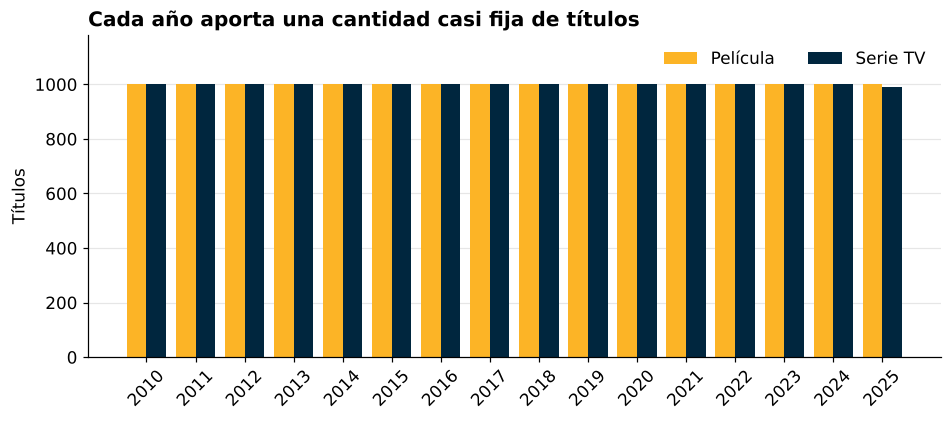

In [7]:
t31 = catalogo.groupby(["release_year", "content_type"]).size().unstack()
display(t31.T)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(t31))
ax.bar(x - 0.2, t31["Película"], width=0.4, color=AMARILLO, label="Película")
ax.bar(x + 0.2, t31["Serie TV"], width=0.4, color=AZUL, label="Serie TV")
ax.set_xticks(x)
ax.set_xticklabels(t31.index, rotation=45)
ax.set_ylabel("Títulos")
ax.set_title("Cada año aporta una cantidad casi fija de títulos", loc="left", fontweight="bold")
ax.set_ylim(0, 1180)
ax.legend(frameon=False, ncol=2, loc="upper right")
estilo(ax)
plt.show()

display(Markdown(f"**Lectura.** Cada año tiene entre **{num(t31.min().min(), 0)} y {num(t31.max().max(), 0)} títulos** por formato. "
                 f"No es que cada año se estrenen exactamente esos títulos: **el catálogo es una muestra con una cantidad parecida por año**. "
                 f"Por eso la cantidad de títulos por año **no sirve para medir crecimiento**; sí sirve comparar la *nota* de cada año."))

> **Decisión que apoya:** en el análisis solo comparamos **promedios y proporciones**, nunca «cuántos títulos hay» como señal de crecimiento.

### 3.2 ¿Qué géneros son más frecuentes?
*Un título puede tener varios géneros: cuenta en cada uno (por eso la suma supera el total de títulos).*

content_type,Película,Serie TV,Total
Drama,6910,7859,14769
Comedia,4533,4572,9105
Animación,1579,2490,4069
Suspenso,3769,0,3769
Acción,3239,0,3239
Crimen,1738,1465,3203
Familia,1472,1542,3014
Misterio,1242,1332,2574
Romance,2571,0,2571
Terror,2425,0,2425


**Lectura.** El género más frecuente es **Drama** (14.769 títulos), seguido de **Comedia** (9.105). Cada formato tiene su propio mapa de géneros: la forma de las barras amarillas y azules no es igual. Por eso la comparación de nota por género (4.3) se limita a los géneros comparables.

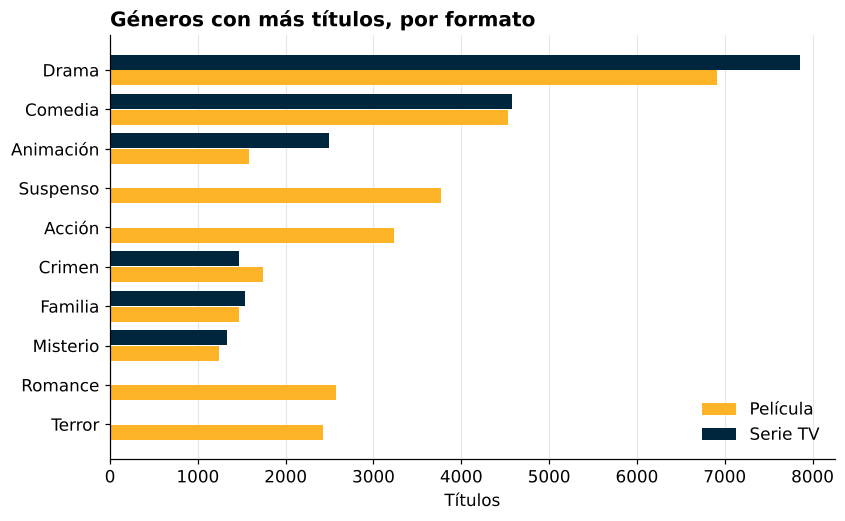

In [8]:
gen = ud.explode_columna(catalogo, "genres")
t32 = gen.groupby(["genres", "content_type"])["id_unico"].nunique().unstack().fillna(0).astype(int)
t32["Total"] = t32.sum(axis=1)
t32 = t32.sort_values("Total", ascending=False).head(10)
t32.index = [ud.es_genero(g) for g in t32.index]
display(t32)

t32p = t32.sort_values("Total")
y = np.arange(len(t32p))
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh(y - 0.2, t32p["Película"], height=0.38, color=AMARILLO, label="Película")
ax.barh(y + 0.2, t32p["Serie TV"], height=0.38, color=AZUL, label="Serie TV")
ax.set_yticks(y)
ax.set_yticklabels(t32p.index)
ax.set_xlabel("Títulos")
ax.set_title("Géneros con más títulos, por formato", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
estilo(ax, "x")
plt.show()

display(Markdown(f"**Lectura.** El género más frecuente es **{t32.index[0]}** ({num(t32.iloc[0]['Total'], 0)} títulos), seguido de **{t32.index[1]}** ({num(t32.iloc[1]['Total'], 0)}). "
                 f"Cada formato tiene su propio mapa de géneros: la forma de las barras amarillas y azules no es igual. "
                 f"Por eso la comparación de nota por género (4.3) se limita a los géneros comparables."))

### 3.3 ¿En qué idiomas y de qué países?

Idioma,Inglés,Chino,Japonés,Coreano,Español,Francés,Alemán,Hindi
porcentaje,43.7,8.9,8.7,7.0,5.1,5.1,2.3,2.0


,Estados Unidos,Japón,Reino Unido,China,Corea del Sur,Francia,Canadá,Alemania
Títulos,10955,2869,2608,2399,2174,2108,1715,1160


**Lectura.** El catálogo tiene **83 idiomas**, pero **Inglés** concentra el 44%. El país con más títulos es **Estados Unidos** (10.955). Hay mucha diversidad, pero con pocos títulos en la mayoría de los idiomas y países: **comparar notas entre países exige cuidado** (sección 7).

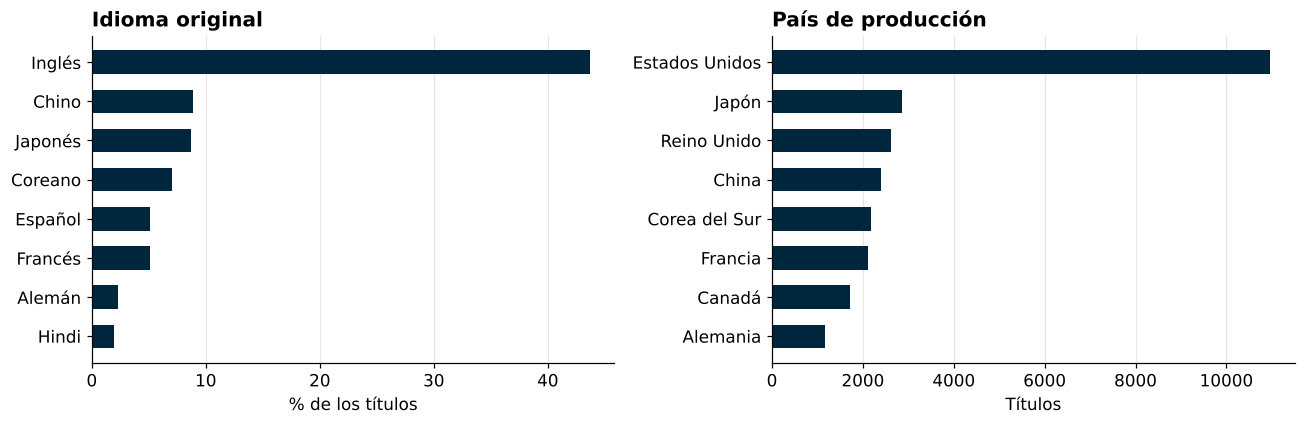

In [9]:
idiomas = ud.tabla_idiomas(catalogo, n=8)
idiomas["Idioma"] = idiomas["idioma"]
paises_cat = ud.explode_columna(catalogo, "country").groupby("country")["id_unico"].nunique().sort_values(ascending=False).head(8)
paises_cat.index = [ud.es_pais(p) for p in paises_cat.index]
display(idiomas[["Idioma", "porcentaje"]].round(1).set_index("Idioma").T)
display(paises_cat.to_frame("Títulos").T)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].barh(idiomas["Idioma"][::-1], idiomas["porcentaje"][::-1], color=AZUL, height=0.6)
axs[0].set_xlabel("% de los títulos")
axs[0].set_title("Idioma original", loc="left", fontweight="bold")
axs[1].barh(paises_cat.index[::-1], paises_cat.values[::-1], color=AZUL, height=0.6)
axs[1].set_xlabel("Títulos")
axs[1].set_title("País de producción", loc="left", fontweight="bold")
for a in axs:
    estilo(a, "x")
plt.tight_layout()
plt.show()

n_idiomas = catalogo["language"].nunique()
display(Markdown(f"**Lectura.** El catálogo tiene **{n_idiomas} idiomas**, pero **{idiomas.iloc[0]['Idioma']}** concentra el {num(idiomas.iloc[0]['porcentaje'], 0)}%. "
                 f"El país con más títulos es **{paises_cat.index[0]}** ({num(paises_cat.iloc[0], 0)}). "
                 f"Hay mucha diversidad, pero con pocos títulos en la mayoría de los idiomas y países: **comparar notas entre países exige cuidado** (sección 7)."))

### 3.4 ¿Cómo se distribuyen la nota y la popularidad? Por qué usamos mediana y escala logarítmica
*Pregunta sobre la forma de una variable → histograma.* Es el gráfico que justifica **dos decisiones de método**: usar la **mediana** y usar **escala logarítmica**.

,promedio,mediana,maximo
content_type,,,
Película,20.4,10.9,3876.0
Serie TV,64.9,36.2,6421.9


**Cómo se lee.** En escala lineal casi todos los títulos quedan pegados a la izquierda: unos pocos títulos con popularidad enorme estiran el eje. En escala logarítmica la forma se abre y se ve el patrón de la mayoría. **Lectura.** El promedio de popularidad del catálogo es **42,6**, pero la mediana es **22,1**: el promedio es 1,9 veces la mediana, es decir, está inflado por pocos títulos. Con la mediana hablamos del título «típico». En la nota, en cambio, promedio y mediana casi coinciden (Películas 6,31 vs. 6,40; Series 7,03 vs. 7,20), así que el promedio sí sirve.

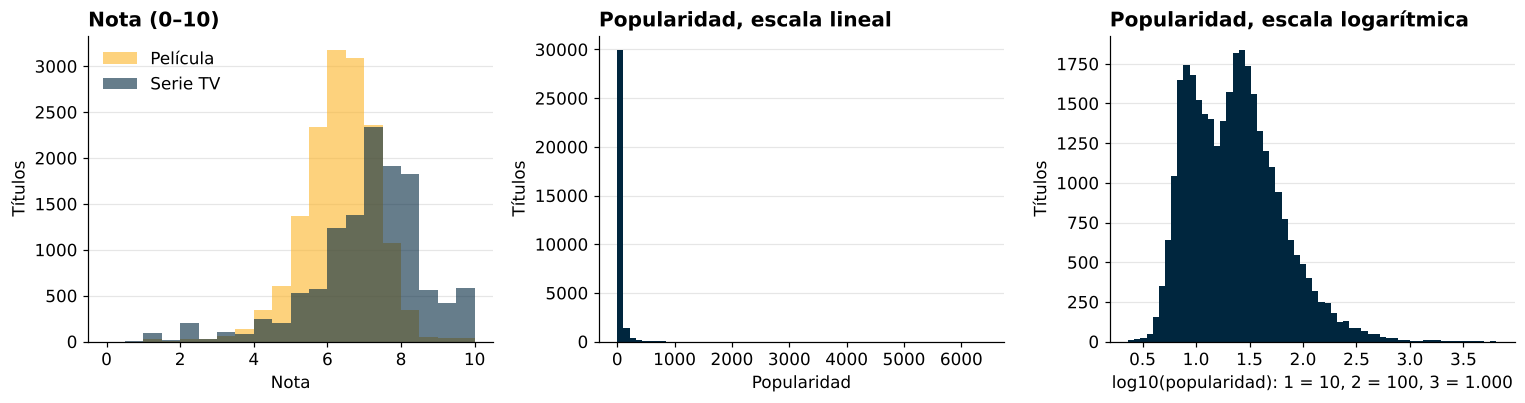

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for f in FORMATOS:
    axs[0].hist(cal[cal["content_type"] == f]["vote_average"], bins=np.arange(0, 10.5, 0.5), alpha=0.6, color=COLOR[f], label=f)
axs[0].set_title("Nota (0–10)", loc="left", fontweight="bold")
axs[0].set_xlabel("Nota")
axs[0].legend(frameon=False)

pop_pos = catalogo[catalogo["popularity"] > 0]["popularity"]
axs[1].hist(pop_pos, bins=60, color=AZUL)
axs[1].set_title("Popularidad, escala lineal", loc="left", fontweight="bold")
axs[1].set_xlabel("Popularidad")

axs[2].hist(np.log10(pop_pos), bins=60, color=AZUL)
axs[2].set_title("Popularidad, escala logarítmica", loc="left", fontweight="bold")
axs[2].set_xlabel("log10(popularidad): 1 = 10, 2 = 100, 3 = 1.000")
for a in axs:
    a.set_ylabel("Títulos")
    estilo(a)
plt.tight_layout()
plt.show()

t34 = catalogo.groupby("content_type")["popularity"].agg(promedio="mean", mediana="median", maximo="max").loc[FORMATOS]
display(t34.round(1))
mediana_total = catalogo["popularity"].median()
prom_total = catalogo["popularity"].mean()
display(Markdown(f"**Cómo se lee.** En escala lineal casi todos los títulos quedan pegados a la izquierda: unos pocos títulos con popularidad enorme estiran el eje. En escala logarítmica la forma se abre y se ve el patrón de la mayoría. "
                 f"**Lectura.** El promedio de popularidad del catálogo es **{num(prom_total, 1)}**, pero la mediana es **{num(mediana_total, 1)}**: el promedio es {num(prom_total / mediana_total, 1)} veces la mediana, "
                 f"es decir, está inflado por pocos títulos. Con la mediana hablamos del título «típico». "
                 f"En la nota, en cambio, promedio y mediana casi coinciden (Películas {num(cal[cal['content_type'] == 'Película']['vote_average'].mean())} vs. {num(cal[cal['content_type'] == 'Película']['vote_average'].median())}; "
                 f"Series {num(cal[cal['content_type'] == 'Serie TV']['vote_average'].mean())} vs. {num(cal[cal['content_type'] == 'Serie TV']['vote_average'].median())}), así que el promedio sí sirve."))

> **Decisión que apoya:** **popularidad con mediana y en escala logarítmica**; **nota con promedio**. Estas dos reglas se repiten en todo el notebook y en el dashboard.

### 3.5 ¿Qué variables se mueven juntas?
*Pregunta sobre relaciones entre varias variables → mapa de calor de correlaciones.* Cada celda dice cuánto se parecen las posiciones de dos variables (de −1 a 1; cerca de 0 = casi sin relación). Usamos **Spearman** porque trabaja con posiciones y no se deja engañar por los valores extremos. Se hace **por formato**, porque mezclar Películas y Series confunde (lo vemos abajo).

**Cómo se lee.** Azul fuerte = se mueven juntas; amarillo = se mueven en sentido contrario; blanco = casi no se relacionan. **Lectura.** (1) En **Películas**, popularidad y votos van juntas (ρ = 0,69) y ambas con los ingresos (0,61 y 0,68). En **Series**, popularidad y votos casi no se parecen (ρ = 0,17): la popularidad mide algo distinto de «cuánta gente votó». (2) **La nota** se relaciona poco con todo: con la popularidad, ρ = 0,27 en Películas y 0,03 en Series; con el año, 0,20 y 0,10. (3) **Presupuesto e ingresos** van unidos (ρ = 0,70), pero eso no dice si conviene (4.6). (4) **Advertencia:** si juntáramos los dos formatos, popularidad y votos saldrían con ρ = -0,18, un resultado engañoso producto de la mezcla.

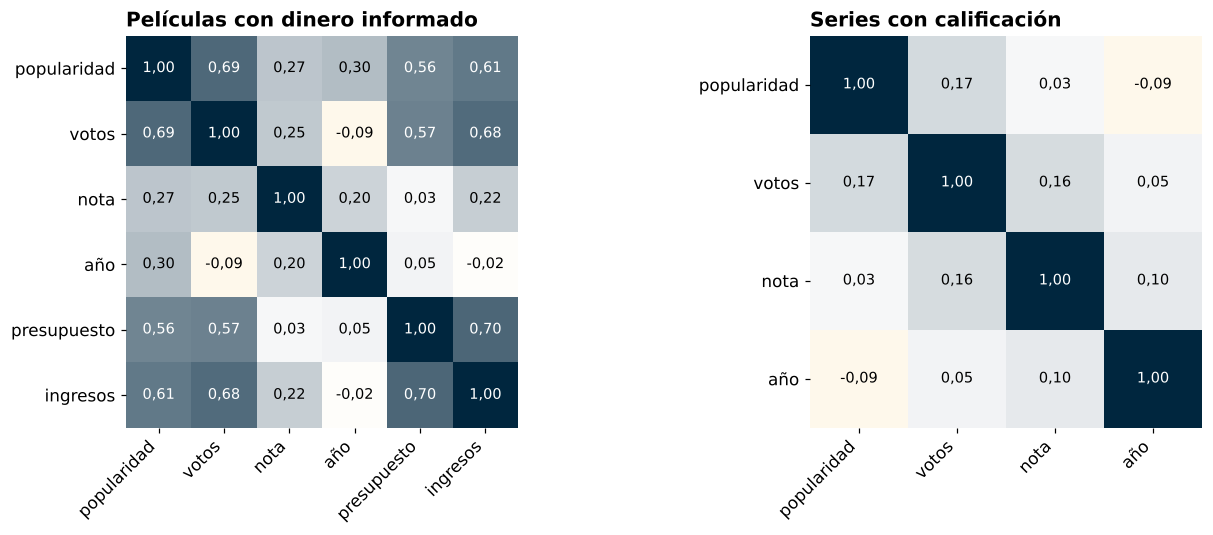

In [11]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("duoc", [AMARILLO, "#FFFFFF", AZUL])
nombres = {"popularity": "popularidad", "vote_count": "votos", "vote_average": "nota", "release_year": "año",
           "budget": "presupuesto", "revenue": "ingresos"}

def mapa(ax, datos, titulo):
    cm = datos.rename(columns=nombres).corr(method="spearman")
    ax.imshow(cm.values, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index)
    for i in range(len(cm)):
        for j in range(len(cm)):
            ax.text(j, i, num(cm.values[i, j]), ha="center", va="center", fontsize=9.5,
                    color="white" if cm.values[i, j] > 0.5 else "black")
    ax.set_title(titulo, loc="left", fontweight="bold")
    ax.spines[:].set_visible(False)
    return cm

fin_3 = ud.datos_financieros(peliculas)   # películas con presupuesto e ingresos ≥ US$ 100.000
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
cm_pel = mapa(axs[0], fin_3[["popularity", "vote_count", "vote_average", "release_year", "budget", "revenue"]], "Películas con dinero informado")
cm_ser = mapa(axs[1], cal[cal["content_type"] == "Serie TV"][["popularity", "vote_count", "vote_average", "release_year"]], "Series con calificación")
plt.tight_layout()
plt.show()

rho_mezcla = cal["popularity"].rank().corr(cal["vote_count"].rank())
display(Markdown(f"**Cómo se lee.** Azul fuerte = se mueven juntas; amarillo = se mueven en sentido contrario; blanco = casi no se relacionan. "
                 f"**Lectura.** (1) En **Películas**, popularidad y votos van juntas (ρ = {num(cm_pel.loc['popularidad', 'votos'])}) y ambas con los ingresos "
                 f"({num(cm_pel.loc['popularidad', 'ingresos'])} y {num(cm_pel.loc['votos', 'ingresos'])}). En **Series**, popularidad y votos casi no se parecen (ρ = {num(cm_ser.loc['popularidad', 'votos'])}): "
                 f"la popularidad mide algo distinto de «cuánta gente votó». "
                 f"(2) **La nota** se relaciona poco con todo: con la popularidad, ρ = {num(cm_pel.loc['popularidad', 'nota'])} en Películas y {num(cm_ser.loc['popularidad', 'nota'])} en Series; con el año, {num(cm_pel.loc['año', 'nota'])} y {num(cm_ser.loc['año', 'nota'])}. "
                 f"(3) **Presupuesto e ingresos** van unidos (ρ = {num(cm_pel.loc['presupuesto', 'ingresos'])}), pero eso no dice si conviene (4.6). "
                 f"(4) **Advertencia:** si juntáramos los dos formatos, popularidad y votos saldrían con ρ = {num(rho_mezcla)}, un resultado engañoso producto de la mezcla."))

> **Decisión que apoya:** la nota y la popularidad miden cosas distintas, así que se analizan por separado y luego se combinan (sección 5). Y **siempre se compara dentro de cada formato**, porque mezclarlos distorsiona las relaciones.

## 4. Análisis principal con gráficos estáticos (IE13)
Un gráfico **estático** sirve para *comunicar* una idea que ya conocemos. Elegimos cada tipo de gráfico según la pregunta: **comparar → barras · tiempo → líneas · relación entre dos variables → dispersión**.

### 4.1 ¿Qué formato se califica mejor?
*Pregunta de comparación → gráfico de barras.*

,titulos,nota_promedio,nota_mediana
content_type,,,
Película,15101,6.31,6.4
Serie TV,12326,7.03,7.2


**Lectura.** Las Series promedian **7,03** y las Películas **6,31**: una ventaja de **0,72 puntos** para las Series (se calcula solo con títulos calificados).

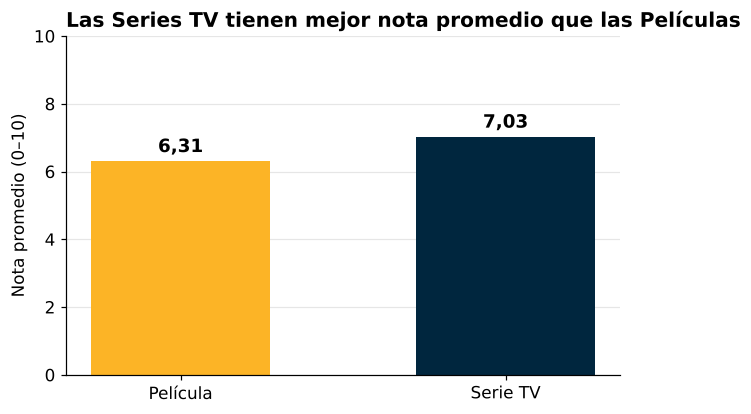

In [12]:
t1 = cal.groupby("content_type")["vote_average"].agg(titulos="size", nota_promedio="mean", nota_mediana="median")
display(t1.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4))
barras = ax.bar(t1.index, t1["nota_promedio"], color=[COLOR[f] for f in t1.index], width=0.55)
ax.bar_label(barras, labels=[num(v) for v in t1["nota_promedio"]], padding=3, fontsize=12, fontweight="bold")
ax.set_ylim(0, 10)
ax.set_ylabel("Nota promedio (0–10)")
ax.set_title("Las Series TV tienen mejor nota promedio que las Películas", loc="left", fontweight="bold")
estilo(ax)
plt.show()

brecha = t1.loc["Serie TV", "nota_promedio"] - t1.loc["Película", "nota_promedio"]
display(Markdown(f"**Lectura.** Las Series promedian **{num(t1.loc['Serie TV', 'nota_promedio'])}** y las Películas **{num(t1.loc['Película', 'nota_promedio'])}**: "
                 f"una ventaja de **{num(brecha)} puntos** para las Series (se calcula solo con títulos calificados)."))

> **Decisión que apoya:** la primera señal es favorable a las Series. Falta comprobar que no sea casualidad de un año o de un género (4.2 y 4.3).

#### Mirándolo con más detalle: ¿es solo el promedio o toda la distribución?
*Pregunta sobre la forma de la nota en cada formato → diagrama de cajas.* La caja cubre al 50% central de los títulos; la línea del medio es la mediana; los puntos son casos extremos.

,Q1 (25%),Mediana,Q3 (75%),Desviación
content_type,,,,
Película,5.73,6.4,7.0,1.01
Serie TV,6.30,7.2,8.0,1.58


**Lectura.** La caja de las Series (de 6,30 a 8,00, mediana 7,20) está desplazada hacia arriba respecto de la de las Películas (de 5,73 a 7,00, mediana 6,40). La diferencia medida en desviaciones estándar es **0,55** (se considera «mediana» desde 0,5): no es un detalle, es un corrimiento de toda la distribución.

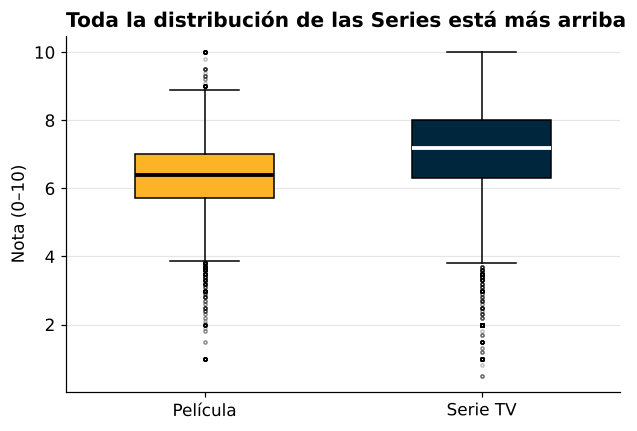

In [13]:
datos_caja = [cal[cal["content_type"] == f]["vote_average"] for f in FORMATOS]
fig, ax = plt.subplots(figsize=(6.5, 4.2))
bp = ax.boxplot(datos_caja, widths=0.5, patch_artist=True, flierprops=dict(marker="o", ms=2, alpha=0.25))
ax.set_xticklabels(FORMATOS)
for caja, mediana, f in zip(bp["boxes"], bp["medians"], FORMATOS):
    caja.set_facecolor(COLOR[f])
    mediana.set_color("black" if f == "Película" else "white")
    mediana.set_linewidth(2.5)
ax.set_ylabel("Nota (0–10)")
ax.set_title("Toda la distribución de las Series está más arriba", loc="left", fontweight="bold")
estilo(ax)
plt.show()

q = cal.groupby("content_type")["vote_average"].describe()[["25%", "50%", "75%", "std"]].loc[FORMATOS]
q.columns = ["Q1 (25%)", "Mediana", "Q3 (75%)", "Desviación"]
display(q.round(2))
p, s_ = datos_caja
d_cohen = (s_.mean() - p.mean()) / np.sqrt(((len(p) - 1) * p.var() + (len(s_) - 1) * s_.var()) / (len(p) + len(s_) - 2))
display(Markdown(f"**Lectura.** La caja de las Series (de {num(q.loc['Serie TV', 'Q1 (25%)'])} a {num(q.loc['Serie TV', 'Q3 (75%)'])}, mediana {num(q.loc['Serie TV', 'Mediana'])}) está desplazada hacia arriba respecto de la de las Películas "
                 f"(de {num(q.loc['Película', 'Q1 (25%)'])} a {num(q.loc['Película', 'Q3 (75%)'])}, mediana {num(q.loc['Película', 'Mediana'])}). "
                 f"La diferencia medida en desviaciones estándar es **{num(d_cohen)}** (se considera «mediana» desde 0,5): no es un detalle, es un corrimiento de toda la distribución."))

### 4.2 ¿Ocurre todos los años?
*Pregunta sobre el tiempo → gráfico de líneas.*

release_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
content_type,,,,,,,,,,,,,,,,
Película,6.12,6.15,6.12,6.20,6.22,6.23,6.23,6.35,6.37,6.46,6.42,6.49,6.41,6.43,6.43,6.50
Serie TV,6.82,6.79,6.89,6.94,6.97,6.88,6.93,6.96,7.05,7.14,7.16,7.03,6.96,7.25,7.42,7.31


**Lectura.** Las Series tienen mejor nota en **16 de 16 años** (2010–2025). La ventaja no depende de un año en particular.

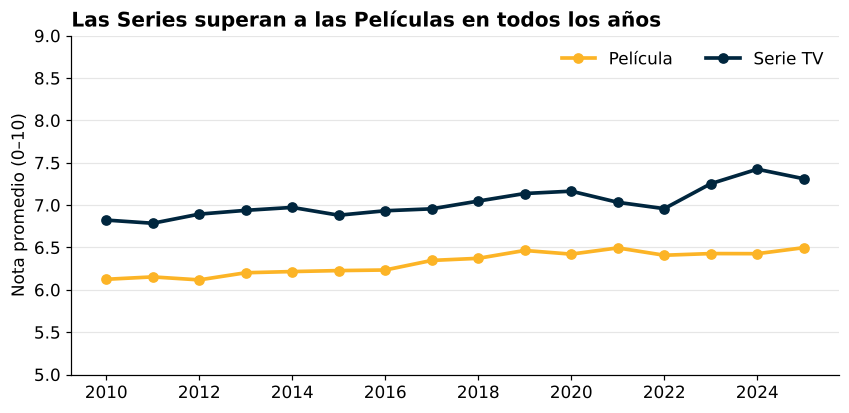

In [14]:
t2 = cal.groupby(["release_year", "content_type"])["vote_average"].mean().unstack()
display(t2.round(2).T)

fig, ax = plt.subplots(figsize=(9, 4))
for f in FORMATOS:
    ax.plot(t2.index, t2[f], marker="o", lw=2.4, color=COLOR[f], label=f)
ax.set_ylim(5, 9)
ax.set_ylabel("Nota promedio (0–10)")
ax.set_title("Las Series superan a las Películas en todos los años", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="upper right", ncol=2)
estilo(ax)
plt.show()

anios_ganan = int((t2["Serie TV"] > t2["Película"]).sum())
display(Markdown(f"**Lectura.** Las Series tienen mejor nota en **{anios_ganan} de {len(t2)} años** ({t2.index.min()}–{t2.index.max()}). "
                 f"La ventaja no depende de un año en particular."))

### 4.3 ¿Ocurre en todos los géneros?
*Pregunta de comparación entre categorías → barras agrupadas.* Solo usamos los **8 géneros que existen con el mismo nombre en ambos formatos**, para que la comparación sea justa.

content_type,Película,Serie TV
Familia,6.68,6.99
Drama,6.46,7.06
Comedia,6.30,7.07
Misterio,6.22,7.21
Crimen,6.35,7.23
Western,6.19,7.26
Animación,6.94,7.34
Documental,7.10,7.42


**Lectura.** Las Series superan a las Películas en **8 de 8 géneros**. El género con la nota más alta en Series es **Documental** (7,42).

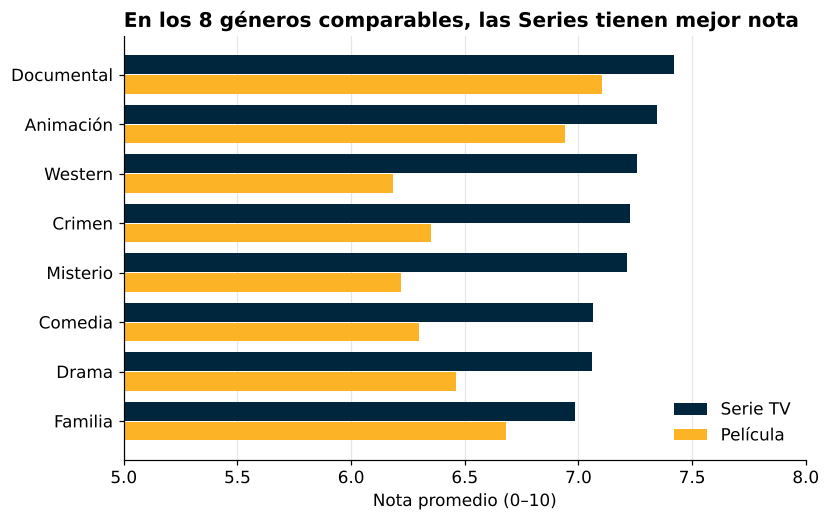

In [15]:
t3 = ud.tabla_generos(catalogo).pivot(index="genres", columns="content_type", values="calif_prom")
t3 = t3.sort_values("Serie TV")
t3.index = [ud.es_genero(g) for g in t3.index]
display(t3.round(2))

y = np.arange(len(t3))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y + 0.2, t3["Serie TV"], height=0.38, color=AZUL, label="Serie TV")
ax.barh(y - 0.2, t3["Película"], height=0.38, color=AMARILLO, label="Película")
ax.set_yticks(y)
ax.set_yticklabels(t3.index)
ax.set_xlim(5, 8)
ax.set_xlabel("Nota promedio (0–10)")
ax.set_title("En los 8 géneros comparables, las Series tienen mejor nota", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
estilo(ax, "x")
plt.show()

generos_ganan = int((t3["Serie TV"] > t3["Película"]).sum())
display(Markdown(f"**Lectura.** Las Series superan a las Películas en **{generos_ganan} de {len(t3)} géneros**. "
                 f"El género con la nota más alta en Series es **{t3['Serie TV'].idxmax()}** ({num(t3['Serie TV'].max())})."))

> **Decisión que apoya:** la ventaja de las Series es **general** (todos los años y todos los géneros), así que la recomendación principal no depende de un caso particular.

### 4.4 ¿Lo popular es también lo mejor evaluado?
*Pregunta de relación entre dos variables → gráfico de dispersión.* La popularidad tiene valores muy dispares (unos pocos títulos enormes), así que usamos **escala logarítmica** en ese eje: cada marca vale 10 veces la anterior y todos los títulos se pueden ver.

,ρ con 0+ votos,ρ con 50+ votos,ρ² (50+ votos)
Todo el catálogo (mezclado),0.32,0.46,0.22
Solo Películas,0.22,0.24,0.06
Solo Series TV,0.03,0.25,0.06


**Lectura.** Dentro de cada formato, la correlación es de **0,24** (Películas) y **0,25** (Series): la popularidad explica solo ~6% de las diferencias de nota. Al mezclar ambos formatos sube a 0,46, pero en parte es un efecto de mezcla: las Series son más calificadas y están en otra zona de popularidad.

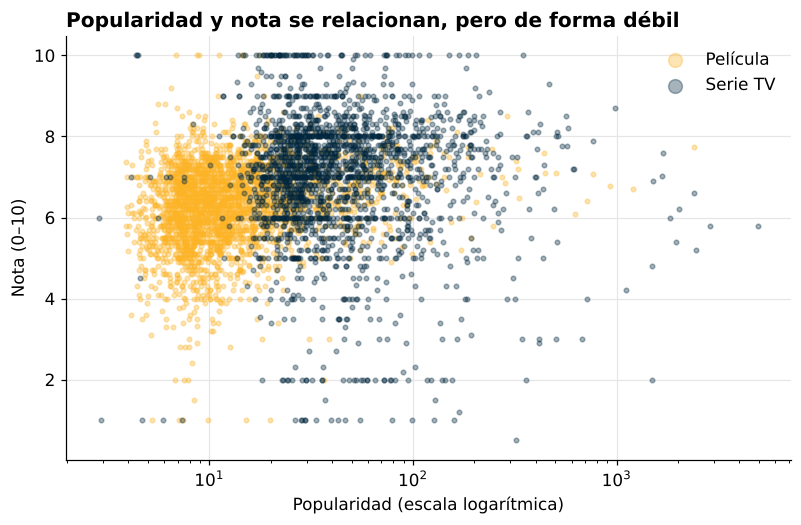

In [16]:
muestra = cal[cal["popularity"] > 0].sample(5000, random_state=1)   # muestra solo para dibujar rápido
fig, ax = plt.subplots(figsize=(8.5, 5))
for f in FORMATOS:
    m = muestra[muestra["content_type"] == f]
    ax.scatter(m["popularity"], m["vote_average"], s=9, alpha=0.35, color=COLOR[f], label=f)
ax.set_xscale("log")
ax.set_xlabel("Popularidad (escala logarítmica)")
ax.set_ylabel("Nota (0–10)")
ax.set_title("Popularidad y nota se relacionan, pero de forma débil", loc="left", fontweight="bold")
ax.legend(frameon=False, markerscale=3)
estilo(ax, "both")
plt.show()

def rho(df):                                             # Spearman: relación por posiciones, no por valores
    return df["popularity"].rank().corr(df["vote_average"].rank())

filas = {"Todo el catálogo (mezclado)": cal, "Solo Películas": cal[cal["content_type"] == "Película"],
         "Solo Series TV": cal[cal["content_type"] == "Serie TV"]}
t4 = pd.DataFrame({nombre: {"ρ con 0+ votos": rho(d), "ρ con 50+ votos": rho(d[d["vote_count"] >= 50]),
                            "ρ² (50+ votos)": rho(d[d["vote_count"] >= 50]) ** 2}
                   for nombre, d in filas.items()}).T
display(t4.round(2))
display(Markdown(f"**Lectura.** Dentro de cada formato, la correlación es de **{num(t4.loc['Solo Películas', 'ρ con 50+ votos'])}** (Películas) y **{num(t4.loc['Solo Series TV', 'ρ con 50+ votos'])}** (Series): "
                 f"la popularidad explica solo ~{num(t4.loc['Solo Películas', 'ρ² (50+ votos)'] * 100, 0)}% de las diferencias de nota. "
                 f"Al mezclar ambos formatos sube a {num(t4.loc['Todo el catálogo (mezclado)', 'ρ con 50+ votos'])}, pero en parte es un efecto de mezcla: las Series son más calificadas y están en otra zona de popularidad."))

> **Decisión que apoya:** **no elegir títulos solo por popularidad.** Para comparar títulos usamos un **índice combinado** (promedio de la posición en popularidad y en nota); se ve en la sección 5.
>
> *(ρ de Spearman va de −1 a 1; cerca de 0 = casi sin relación. ρ² es la parte de la variación que se explica.)*

In [17]:
t44 = cal.groupby("content_type").agg(titulos=("id_unico", "size"), popularidad_mediana=("popularity", "median"),
                                        nota_promedio=("vote_average", "mean")).loc[FORMATOS]
display(t44.round(2))
display(Markdown(f"**Por qué la correlación «mezclada» engaña.** Las Series tienen popularidad mediana **{num(t44.loc['Serie TV', 'popularidad_mediana'], 1)}** y nota **{num(t44.loc['Serie TV', 'nota_promedio'])}**; "
                 f"las Películas, **{num(t44.loc['Película', 'popularidad_mediana'], 1)}** y **{num(t44.loc['Película', 'nota_promedio'])}**. "
                 f"En el gráfico, la nube azul está arriba a la derecha y la amarilla abajo a la izquierda: al juntarlas **parece** que más popularidad implica más nota (ρ = {num(t4.loc['Todo el catálogo (mezclado)', 'ρ con 50+ votos'])}), "
                 f"pero dentro de cada nube la relación es mucho menor (ρ ≈ {num(t4.loc['Solo Películas', 'ρ con 50+ votos'])} y {num(t4.loc['Solo Series TV', 'ρ con 50+ votos'])}). "
                 f"Por eso siempre **comparamos dentro de cada formato**."))

,titulos,popularidad_mediana,nota_promedio
content_type,,,
Película,15101,11.08,6.31
Serie TV,12326,37.94,7.03


**Por qué la correlación «mezclada» engaña.** Las Series tienen popularidad mediana **37,9** y nota **7,03**; las Películas, **11,1** y **6,31**. En el gráfico, la nube azul está arriba a la derecha y la amarilla abajo a la izquierda: al juntarlas **parece** que más popularidad implica más nota (ρ = 0,46), pero dentro de cada nube la relación es mucho menor (ρ ≈ 0,24 y 0,25). Por eso siempre **comparamos dentro de cada formato**.

### 4.5 ¿De dónde vienen las Series mejor evaluadas?
*Comparar países → barras.* Solo se comparan países con **al menos 100 Series con 50+ votos**; con menos títulos, el promedio de un país no es confiable (lo mostramos en la tabla).

,Series (total),Series con 50+ votos,Nota prom. (50+ votos)
Estados Unidos,3193,1635,7.37
China,1900,39,8.11
Japón,1879,582,7.85
Corea del Sur,1299,277,7.94
Reino Unido,865,345,7.37
Canadá,652,144,7.33
Alemania,469,67,7.33
Francia,407,92,7.40
Filipinas,401,5,7.04
India,384,22,7.42


**Lectura.** Entre los países con base suficiente, el mejor promedio es **Corea del Sur** (7,94) y el más bajo **Canadá** (7,33). **Cuidado con China:** tiene 1.900 Series, pero solo 39 con 50+ votos; su promedio no se puede comparar con confianza.

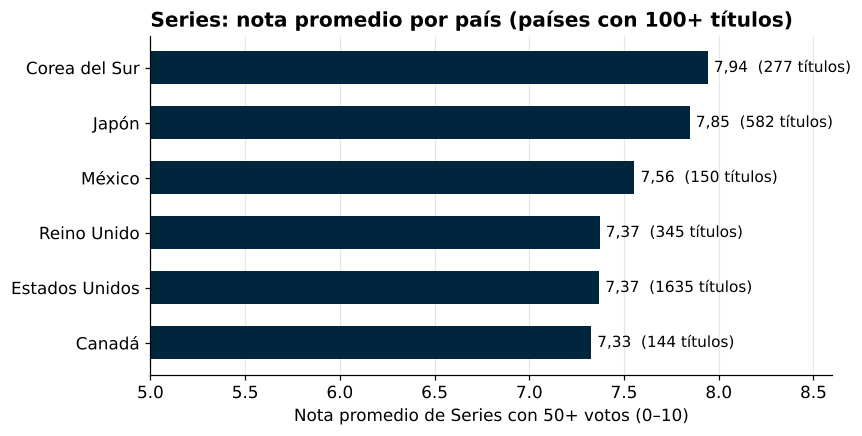

In [18]:
s50 = ud.explode_columna(cal[(cal["content_type"] == "Serie TV") & (cal["vote_count"] >= 50)], "country")
t5_todos = s50.groupby("country").agg(titulos_50=("id_unico", "nunique"), nota_50=("vote_average", "mean"))
paises = ud.tabla_paises_series(catalogo, n=12).set_index("country").join(t5_todos)
paises.index = [ud.es_pais(p) for p in paises.index]
display(paises[["titulos", "titulos_50_votos", "nota_50"]].rename(columns={
    "titulos": "Series (total)", "titulos_50_votos": "Series con 50+ votos", "nota_50": "Nota prom. (50+ votos)"}).round(2))

t5 = t5_todos[t5_todos["titulos_50"] >= 100].rename(columns={"titulos_50": "titulos", "nota_50": "nota"}).sort_values("nota")
t5.index = [ud.es_pais(p) for p in t5.index]

fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.barh(t5.index, t5["nota"], color=AZUL, height=0.6)
ax.bar_label(barras, labels=[f"{num(n)}  ({int(t)} títulos)" for n, t in zip(t5["nota"], t5["titulos"])], padding=4, fontsize=10)
ax.set_xlim(5, 8.6)
ax.set_xlabel("Nota promedio de Series con 50+ votos (0–10)")
ax.set_title("Series: nota promedio por país (países con 100+ títulos)", loc="left", fontweight="bold")
estilo(ax, "x")
plt.show()

display(Markdown(f"**Lectura.** Entre los países con base suficiente, el mejor promedio es **{t5['nota'].idxmax()}** ({num(t5['nota'].max())}) y el más bajo **{t5['nota'].idxmin()}** ({num(t5['nota'].min())}). "
                 f"**Cuidado con China:** tiene {num(int(paises.loc['China', 'titulos']), 0)} Series, pero solo {int(paises.loc['China', 'titulos_50_votos'])} con 50+ votos; su promedio no se puede comparar con confianza."))

### 4.6 Complemento: ¿qué géneros de películas devuelven más dinero?
*Solo películas que informan presupuesto e ingresos (≥ US$ 100.000 cada uno).* El **ROI** es cuántas veces se recupera lo invertido: ingresos ÷ presupuesto (2× = se recupera el doble). *Este análisis es complementario: no cambia la decisión principal y no se presenta en los 10 minutos.*

In [19]:
din = peliculas[(peliculas["budget"] > 0) & (peliculas["revenue"] > 0)].copy()
din["roi"] = din["revenue"] / din["budget"]
simbolicas = din[(din["budget"] < ud.UMBRAL_FINANCIERO) | (din["revenue"] < ud.UMBRAL_FINANCIERO)]
usadas = din.drop(simbolicas.index)
t46 = pd.DataFrame({
    "Películas": [len(peliculas), len(din), len(simbolicas), len(usadas)],
    "ROI más alto (veces)": [np.nan, din["roi"].max(), simbolicas["roi"].max(), usadas["roi"].max()],
}, index=["Películas en total", "Con presupuesto e ingresos informados (> 0)", "…con algún monto simbólico (< US$ 100.000): se descartan", "…con ambos ≥ US$ 100.000: las que usamos"])
display(t46.round(1))
display(Markdown(f"**Por qué el umbral de US$ 100.000.** Entre las películas con dinero informado, **{num(len(simbolicas), 0)}** tienen algún monto simbólico y llegan a retornos de hasta **{num(simbolicas['roi'].max(), 0)}×**; "
                 f"entre las que usamos, el máximo es **{num(usadas['roi'].max(), 0)}×**. Sin el umbral, esos casos distorsionarían cualquier promedio."))

,Películas,ROI más alto (veces)
Películas en total,16000,NaN
Con presupuesto e ingresos informados (> 0),3540,2456760.0
…con algún monto simbólico (< US$ 100.000): se descartan,178,2456760.0
…con ambos ≥ US$ 100.000: las que usamos,3362,559.1


**Por qué el umbral de US$ 100.000.** Entre las películas con dinero informado, **178** tienen algún monto simbólico y llegan a retornos de hasta **2.456.760×**; entre las que usamos, el máximo es **559×**. Sin el umbral, esos casos distorsionarían cualquier promedio.

,titulos,roi_mediano
Género,,
Terror,422,2.50
Animación,281,2.37
Familia,381,2.19
Ciencia ficción,365,2.15
Comedia,1101,2.11
Aventura,688,2.06
Música,100,2.00
Acción,953,1.93
Fantasía,376,1.92


**Lectura.** Solo **3.362 películas (21%)** informan dinero de forma confiable. El ROI mediano global es **1,81×** y **66%** recupera más de lo invertido. Mejor género: **Terror** (2,50×); peor: **Historia** (1,17×). Como solo cubre una parte de las películas y ninguna serie, se usa como apoyo, no como criterio principal.

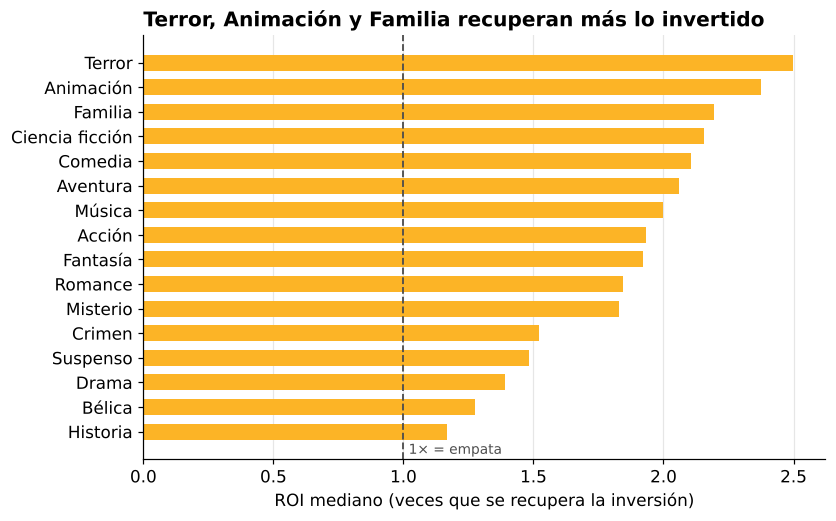

In [20]:
fin = ud.datos_financieros(peliculas)
fin_gen = ud.roi_por_genero(fin, min_n=100).sort_values("roi_mediano")
fin_gen["Género"] = fin_gen["genres"].map(ud.es_genero)
cobertura = len(fin) / len(peliculas)
display(fin_gen[["Género", "titulos", "roi_mediano"]].round(2).set_index("Género").sort_values("roi_mediano", ascending=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(fin_gen["Género"], fin_gen["roi_mediano"], color=AMARILLO, height=0.65)
ax.axvline(1, color="#4D4D4D", lw=1.2, ls="--")
ax.text(1.02, -0.9, "1× = empata", fontsize=9, color="#4D4D4D")
ax.set_xlabel("ROI mediano (veces que se recupera la inversión)")
ax.set_title(f"{fin_gen.iloc[-1]['Género']}, {fin_gen.iloc[-2]['Género']} y {fin_gen.iloc[-3]['Género']} recuperan más lo invertido", loc="left", fontweight="bold")
estilo(ax, "x")
plt.show()

display(Markdown(f"**Lectura.** Solo **{num(len(fin), 0)} películas ({num(cobertura * 100, 0)}%)** informan dinero de forma confiable. "
                 f"El ROI mediano global es **{num(fin['roi'].median())}×** y **{num((fin['roi'] > 1).mean() * 100, 0)}%** recupera más de lo invertido. "
                 f"Mejor género: **{fin_gen.iloc[-1]['Género']}** ({num(fin_gen.iloc[-1]['roi_mediano'])}×); peor: **{fin_gen.iloc[0]['Género']}** ({num(fin_gen.iloc[0]['roi_mediano'])}×). "
                 f"Como solo cubre una parte de las películas y ninguna serie, se usa como apoyo, no como criterio principal."))

**Cómo se lee.** La línea punteada es ROI = 1×. Los puntos **sobre** la línea recuperaron más de lo que costaron (66% de las películas del gráfico); los de **abajo**, menos. La nube sube hacia la derecha (más presupuesto se asocia con más ingresos, ρ = 0,70), pero **muchos puntos con presupuesto alto quedan bajo la línea**: gastar más no garantiza ganar más.

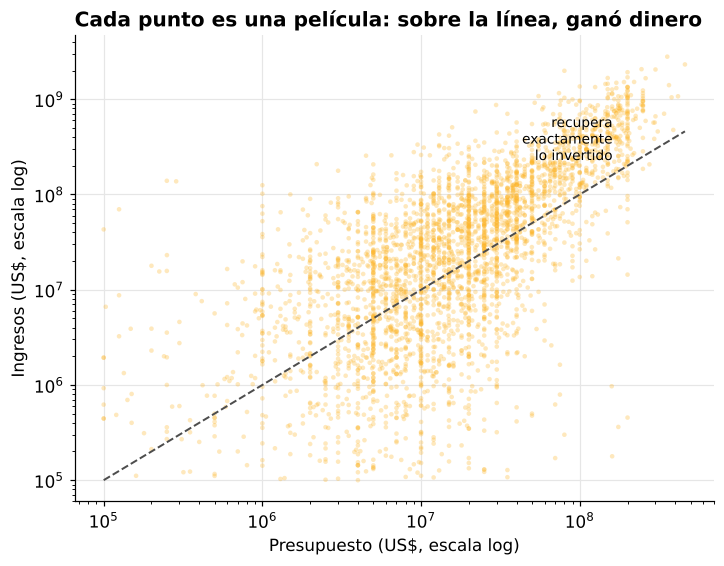

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(fin["budget"], fin["revenue"], s=9, alpha=0.3, color=AMARILLO, edgecolor="none")
ax.set_xscale("log")
ax.set_yscale("log")
lim = [fin["budget"].min(), fin["budget"].max()]
ax.plot(lim, lim, "--", color="#4D4D4D", lw=1.3)
ax.text(lim[1] * 0.35, lim[1] * 0.5, "recupera\nexactamente\nlo invertido", fontsize=9, ha="right")
ax.set_xlabel("Presupuesto (US$, escala log)")
ax.set_ylabel("Ingresos (US$, escala log)")
ax.set_title("Cada punto es una película: sobre la línea, ganó dinero", loc="left", fontweight="bold")
estilo(ax, "both")
plt.show()
display(Markdown(f"**Cómo se lee.** La línea punteada es ROI = 1×. Los puntos **sobre** la línea recuperaron más de lo que costaron ({num((fin['roi'] > 1).mean() * 100, 0)}% de las películas del gráfico); los de **abajo**, menos. "
                 f"La nube sube hacia la derecha (más presupuesto se asocia con más ingresos, ρ = {num(cm_pel.loc['presupuesto', 'ingresos'])}), pero **muchos puntos con presupuesto alto quedan bajo la línea**: gastar más no garantiza ganar más."))

## 5. Índice combinado: elegir títulos mirando popularidad y nota a la vez
**Por qué existe.** En 4.4 vimos que popularidad y nota se relacionan poco: un título puede ser muy visto y mal evaluado, o muy bien evaluado y poco visto. Si ordenamos por una sola, elegimos mal. El **índice combinado** pone las dos en la misma escala y las promedia.

**Cómo se calcula (paso a paso)**
1. Se toman solo los títulos con calificación y **50+ votos** (para que la nota sea confiable).
2. Cada título recibe su **posición en popularidad** de 0 a 100 (100 = el más popular).
3. Cada título recibe su **posición en nota** de 0 a 100 (100 = la mejor nota).
4. El **índice** es el promedio de ambas posiciones (0 a 100).

Usamos posiciones y no los valores directos porque popularidad (de 0 a miles) y nota (de 0 a 10) están en escalas distintas.

In [22]:
base_ind = cal[cal["vote_count"] >= 50].copy()
base_ind["pos_popularidad"] = base_ind["popularity"].rank(pct=True) * 100
base_ind["pos_nota"] = base_ind["vote_average"].rank(pct=True) * 100
base_ind["indice"] = (base_ind["pos_popularidad"] + base_ind["pos_nota"]) / 2
top10_ind = base_ind.nlargest(10, "indice")
display(top10_ind[["title", "content_type", "release_year", "popularity", "vote_average", "vote_count", "pos_popularidad", "pos_nota", "indice"]]
        .rename(columns={"title": "Título", "content_type": "Formato", "release_year": "Año", "popularity": "Popularidad", "vote_average": "Nota",
                         "vote_count": "Votos", "pos_popularidad": "Pos. popularidad", "pos_nota": "Pos. nota", "indice": "Índice"})
        .round(1).reset_index(drop=True))

solo_pop = base_ind.nlargest(1, "popularity").iloc[0]
solo_nota = base_ind.sort_values(["vote_average", "vote_count"], ascending=False).iloc[0]
display(Markdown(f"**Lectura.** Si ordenáramos **solo por popularidad**, el primero sería «{solo_pop['title']}» (nota {num(solo_pop['vote_average'], 1)}); "
                 f"**solo por nota**, «{solo_nota['title']}» (popularidad {num(solo_nota['popularity'], 0)}); "
                 f"con el **índice**, «{top10_ind.iloc[0]['title']}», que está arriba en las dos."))

,Título,Formato,Año,Popularidad,Nota,Votos,Pos. popularidad,Pos. nota,Índice
0,Rick and Morty,Serie TV,2013,984.1,8.7,9992,99.8,99.8,99.8
1,INVINCIBLE,Serie TV,2021,824.1,8.6,4660,99.8,99.7,99.8
2,Solo Leveling,Serie TV,2024,1781.3,8.5,797,99.9,99.3,99.6
3,Regular Show,Serie TV,2010,426.1,8.6,2045,99.3,99.7,99.5
4,The Rookie,Serie TV,2018,1008.2,8.5,2289,99.8,99.0,99.4
5,Run BTS!,Serie TV,2015,367.1,8.6,362,99.2,99.6,99.4
6,Game of Thrones,Serie TV,2011,812.2,8.5,24664,99.8,99.0,99.4
7,Better Call Saul,Serie TV,2015,286.5,8.7,5475,98.9,99.8,99.4
8,The Apothecary Diaries,Serie TV,2023,270.7,8.7,251,98.8,99.8,99.3
9,The Amazing World of Gumball,Serie TV,2011,561.1,8.5,1472,99.6,99.0,99.3


**Lectura.** Si ordenáramos **solo por popularidad**, el primero sería «The Late Show with Stephen Colbert» (nota 6,5); **solo por nota**, «Nude» (popularidad 27); con el **índice**, «Rick and Morty», que está arriba en las dos.

#### ¿Depende el resultado de que los pesos sean 50% y 50%? Prueba de sensibilidad

In [23]:
filas = []
for w in (0.3, 0.4, 0.5, 0.6, 0.7):
    punt = w * base_ind["pos_popularidad"] + (1 - w) * base_ind["pos_nota"]
    t = base_ind.loc[punt.nlargest(10).index]
    filas.append({"Peso popularidad": f"{int(w * 100)}%", "Peso nota": f"{100 - int(w * 100)}%",
                  "Títulos en común con el top 10 base": len(set(t["id_unico"]) & set(top10_ind["id_unico"])),
                  "Series entre los 10": int((t["content_type"] == "Serie TV").sum()), "N.º 1": t.iloc[0]["title"]})
sens = pd.DataFrame(filas).set_index("Peso popularidad")
display(sens)
display(Markdown(f"**Lectura.** Cambiando los pesos entre 30/70 y 70/30, **entre {sens['Títulos en común con el top 10 base'].min()} y {sens['Títulos en común con el top 10 base'].max()} de los 10 títulos se mantienen**, "
                 f"y el número de Series entre los 10 es {sens['Series entre los 10'].min() if sens['Series entre los 10'].min() == sens['Series entre los 10'].max() else str(sens['Series entre los 10'].min()) + ' a ' + str(sens['Series entre los 10'].max())}. "
                 f"El ranking no es un truco de pesos: es estable. Las Series dominan el top porque están arriba en popularidad **y** en nota; para ver el mejor de cada formato, el dashboard permite filtrar por formato."))

,Peso nota,Títulos en común con el top 10 base,Series entre los 10,N.º 1
Peso popularidad,,,,
30%,70%,7,10,Rick and Morty
40%,60%,9,10,Rick and Morty
50%,50%,10,10,Rick and Morty
60%,40%,8,10,Rick and Morty
70%,30%,8,10,Rick and Morty


**Lectura.** Cambiando los pesos entre 30/70 y 70/30, **entre 7 y 10 de los 10 títulos se mantienen**, y el número de Series entre los 10 es 10. El ranking no es un truco de pesos: es estable. Las Series dominan el top porque están arriba en popularidad **y** en nota; para ver el mejor de cada formato, el dashboard permite filtrar por formato.

> **Decisión que apoya:** usamos el **índice combinado con pesos iguales** como criterio por defecto de rankings, tanto en el dashboard como en la infografía.

## 6. Análisis con gráficos interactivos (IE14)
Un gráfico **interactivo** sirve para *explorar*: el usuario hace sus propias preguntas. Usamos **Plotly** y solo dos gráficos; cada uno agrega algo que el estático no puede dar.

| Elemento de interacción | Cómo se usa | Para qué sirve |
|---|---|---|
| **Tooltip** | Pasar el cursor sobre un punto | Ver el título, año y votos exactos |
| **Leyenda clicable** | Clic en «Película» o «Serie TV» | Aislar un formato |
| **Zoom** | Arrastrar un recuadro (doble clic = volver) | Acercarse a una zona |
| **Botones** | Clic en «10+ votos», «50+ votos»… | Cambiar el filtro sin reescribir código |

### 6.1 Cada punto es un título (versión interactiva de 4.4)
*Con el cursor se identifica cualquier título; con la leyenda se aísla un formato.*

In [ ]:
import plotly.express as px

pts = cal[(cal["vote_count"] >= 50) & (cal["popularity"] > 0)].sample(3000, random_state=1).copy()
pts["Formato"] = pts["content_type"]
fig1 = px.scatter(
    pts, x="popularity", y="vote_average", color="Formato", color_discrete_map=COLOR, log_x=True,
    hover_name="title", opacity=0.6,
    hover_data={"release_year": True, "vote_count": ":,", "popularity": ":.1f", "vote_average": ":.1f", "Formato": False},
    labels={"popularity": "Popularidad (escala log)", "vote_average": "Nota (0–10)", "release_year": "Año", "vote_count": "Votos"},
    title="Popularidad vs. nota (muestra de 3.000 títulos con 50+ votos)",
)
fig1.update_layout(template="plotly_white", height=480, legend_title_text="Clic para ocultar")
fig1.show()

### 6.2 Los 10 títulos con mejor nota, según los votos mínimos
*Los botones cambian el mínimo de votos. Observa cómo cambia la lista: esto responde la sección 7.*

In [ ]:
import plotly.graph_objects as go

umbrales = [0, 10, 50, 100]
fig2 = go.Figure()
for i, u_min in enumerate(umbrales):
    top = (cal[cal["vote_count"] >= u_min]
           .sort_values(["vote_average", "vote_count"], ascending=False).head(10).iloc[::-1])
    fig2.add_trace(go.Bar(
        x=top["vote_average"], y=top["title"].str.slice(0, 38), orientation="h", visible=(i == 0),
        marker_color=[COLOR[f] for f in top["content_type"]],
        customdata=np.stack([top["vote_count"], top["content_type"]], axis=-1),
        hovertemplate="%{y}<br>Nota %{x:.1f}<br>%{customdata[0]:,} votos · %{customdata[1]}<extra></extra>"))
botones = [dict(label=f"{u_min}+ votos", method="update",
                args=[{"visible": [j == i for j in range(len(umbrales))]}]) for i, u_min in enumerate(umbrales)]
fig2.update_layout(template="plotly_white", height=460, xaxis_range=[0, 10.5], xaxis_title="Nota (0–10)",
                   title="Top 10 por nota: cambia el mínimo de votos con los botones",
                   updatemenus=[dict(type="buttons", direction="right", x=0, y=1.15, buttons=botones)])
fig2.show()

## 7. ¿Es necesario fijar un mínimo de votos?
**Respuesta corta: no para la decisión principal; sí para rankings y correlaciones.** Es una **regla de confiabilidad**, no un requisito para llegar a las decisiones. Lo comprobamos con datos en cuatro pruebas.

*¿Por qué existe?* Una nota basada en 2 votos puede ser un 10 por casualidad; una nota con 5.000 votos es estable.

#### Prueba 1 · ¿Cambia la decisión principal si NO exigimos votos?

In [24]:
t_b = ud.brecha_por_votos(catalogo, umbrales=(0, 10, 50, 100, 500)).set_index("votos_min")
t_b = t_b.rename(columns={"n_pelicula": "Películas (n)", "n_serie": "Series (n)", "calif_pelicula": "Nota Películas",
                          "calif_serie": "Nota Series", "brecha": "Ventaja de Series"})
display(t_b.round(2))

def contar(votos):
    c = cal[cal["vote_count"] >= votos]
    anio = c.groupby(["release_year", "content_type"])["vote_average"].mean().unstack()
    gen = ud.tabla_generos(c).pivot(index="genres", columns="content_type", values="calif_prom")
    return int((anio["Serie TV"] > anio["Película"]).sum()), len(anio), int((gen["Serie TV"] > gen["Película"]).sum()), len(gen)

res = pd.DataFrame({f"{v}+ votos": contar(v) for v in (0, 50)}, index=["Años con Series arriba", "de años", "Géneros con Series arriba", "de géneros"]).T
display(res)
display(Markdown(f"**Conclusión de la prueba 1.** Sin exigir ningún voto, las Series ya superan a las Películas por **{num(t_b.loc[0, 'Ventaja de Series'])} puntos**, en {res.loc['0+ votos'].iloc[0]} de {res.loc['0+ votos'].iloc[1]} años y {res.loc['0+ votos'].iloc[2]} de {res.loc['0+ votos'].iloc[3]} géneros. "
                 f"Al exigir 50+ votos la ventaja sube a **{num(t_b.loc[50, 'Ventaja de Series'])}**: el mínimo la *aclara*, pero **no la crea ni la cambia**."))

,Películas (n),Series (n),Nota Películas,Nota Series,Ventaja de Series
votos_min,,,,,
0,15101,12326,6.31,7.03,0.72
10,14183,6148,6.35,7.29,0.94
50,12185,3212,6.39,7.52,1.13
100,9528,2277,6.46,7.63,1.17
500,3564,680,6.64,7.90,1.25


,Años con Series arriba,de años,Géneros con Series arriba,de géneros
0+ votos,16,16,8,8
50+ votos,16,16,8,8


**Conclusión de la prueba 1.** Sin exigir ningún voto, las Series ya superan a las Películas por **0,72 puntos**, en 16 de 16 años y 8 de 8 géneros. Al exigir 50+ votos la ventaja sube a **1,13**: el mínimo la *aclara*, pero **no la crea ni la cambia**.

#### Prueba 2 · ¿Cambia la correlación popularidad–nota?

In [25]:
t_c = pd.DataFrame({
    "Películas": {f"{v}+ votos": rho(cal[(cal["content_type"] == "Película") & (cal["vote_count"] >= v)]) for v in (0, 10, 50, 100, 200)},
    "Series TV": {f"{v}+ votos": rho(cal[(cal["content_type"] == "Serie TV") & (cal["vote_count"] >= v)]) for v in (0, 10, 50, 100, 200)},
})
display(t_c.round(2))
display(Markdown(f"**Conclusión de la prueba 2.** En Series la correlación pasa de **{num(t_c.loc['0+ votos', 'Series TV'])}** (sin mínimo) a **{num(t_c.loc['50+ votos', 'Series TV'])}** (50+ votos) y después se estabiliza. "
                 f"Con pocos votos, las notas son ruido y ocultan la relación real. **Aquí el mínimo sí importa.**"))

,Películas,Series TV
0+ votos,0.22,0.03
10+ votos,0.23,0.17
50+ votos,0.24,0.25
100+ votos,0.23,0.28
200+ votos,0.23,0.27


**Conclusión de la prueba 2.** En Series la correlación pasa de **0,03** (sin mínimo) a **0,25** (50+ votos) y después se estabiliza. Con pocos votos, las notas son ruido y ocultan la relación real. **Aquí el mínimo sí importa.**

#### Prueba 3 · ¿Qué pasa con los rankings («los mejores títulos»)?

In [26]:
def top_nota(votos, n=8):
    t = cal[cal["vote_count"] >= votos].sort_values(["vote_average", "vote_count"], ascending=False).head(n)
    return t[["title", "content_type", "vote_average", "vote_count"]].rename(
        columns={"title": "Título", "content_type": "Formato", "vote_average": "Nota", "vote_count": "Votos"}).reset_index(drop=True)

print("Mejores notas SIN mínimo de votos (0+):")
display(top_nota(0))
print("Mejores notas CON mínimo de 100 votos:")
display(top_nota(100))
sin_min = cal.sort_values(["vote_average", "vote_count"], ascending=False).head(50)
display(Markdown(f"**Conclusión de la prueba 3.** Sin mínimo, el «top» está lleno de títulos con muy pocos votos (en los 50 primeros, la mediana de votos es **{num(sin_min['vote_count'].median(), 0)}**). "
                 f"Con 100+ votos, la lista pasa a ser de títulos que mucha gente evaluó. **Para rankings el mínimo sí es necesario.**"))

Mejores notas SIN mínimo de votos (0+):
Mejores notas CON mínimo de 100 votos:


,Título,Formato,Nota,Votos
0,Al Kherbah,Serie TV,10.0,5
1,My Crazy Ex,Serie TV,10.0,5
2,Slunečná,Serie TV,10.0,5
3,Boo! A Call for Adventure,Serie TV,10.0,4
4,Five Minutes of Silence,Serie TV,10.0,4
5,WWE Raw Top 10,Serie TV,10.0,4
6,The Williams,Película,10.0,3
7,Balota,Película,10.0,3


,Título,Formato,Nota,Votos
0,Nude,Película,9.5,161
1,Succubus,Película,9.5,157
2,Kill Shot,Película,9.3,158
3,Break the Silence: The Movie,Película,9.0,183
4,The Three Deaths of Marisela Escobedo,Película,8.9,228
5,Adventure Time: Fionna & Cake,Serie TV,8.9,208
6,BTS: Permission to Dance on Stage - LA,Película,8.9,157
7,The Good Bad Mother,Serie TV,8.9,149


**Conclusión de la prueba 3.** Sin mínimo, el «top» está lleno de títulos con muy pocos votos (en los 50 primeros, la mediana de votos es **2**). Con 100+ votos, la lista pasa a ser de títulos que mucha gente evaluó. **Para rankings el mínimo sí es necesario.**

#### Prueba 4 · ¿Y al comparar países?

In [27]:
ser = cal[cal["content_type"] == "Serie TV"]
x0 = ud.explode_columna(ser, "country")
x50 = ud.explode_columna(ser[ser["vote_count"] >= 50], "country")
t_p = (x0.groupby("country").agg(series=("id_unico", "nunique"), nota_sin_minimo=("vote_average", "mean"))
       .join(x50.groupby("country").agg(series_50=("id_unico", "nunique"), nota_50=("vote_average", "mean")))
       .sort_values("series", ascending=False).head(8))
t_p.index = [ud.es_pais(p) for p in t_p.index]
t_p["series_50"] = t_p["series_50"].astype(int)
t_p["Posición sin mínimo"] = t_p["nota_sin_minimo"].rank(ascending=False).astype(int)
t_p["Posición con 50+"] = t_p["nota_50"].rank(ascending=False).astype(int)
display(t_p.rename(columns={"series": "Series", "nota_sin_minimo": "Nota sin mínimo", "series_50": "Series con 50+ votos", "nota_50": "Nota con 50+ votos"}).round(2))
display(Markdown(f"**Conclusión de la prueba 4.** Corea del Sur pasa del puesto **{t_p.loc['Corea del Sur', 'Posición sin mínimo']}** (nota {num(t_p.loc['Corea del Sur', 'nota_sin_minimo'])}) al puesto **{t_p.loc['Corea del Sur', 'Posición con 50+']}** (nota {num(t_p.loc['Corea del Sur', 'nota_50'])}): "
                 f"sin mínimo, muchas de sus Series tienen pocos votos y bajan el promedio. China tiene la nota más alta con 50+ votos ({num(t_p.loc['China', 'nota_50'])}), pero solo **{t_p.loc['China', 'series_50']} Series** llegan a ese mínimo, así que no se puede recomendar con confianza. "
                 f"**Al comparar países, el mínimo cambia la conclusión: es necesario.**"))

,Series,Nota sin mínimo,Series con 50+ votos,Nota con 50+ votos,Posición sin mínimo,Posición con 50+
Estados Unidos,3015,7.08,1635,7.37,3,7
Japón,1705,7.37,582,7.85,1,3
China,1387,7.27,39,8.11,2,1
Corea del Sur,1162,6.87,277,7.94,7,2
Reino Unido,783,6.98,345,7.37,6,6
Canadá,467,6.78,144,7.33,8,8
Francia,329,7.04,92,7.40,5,5
Turquía,293,7.07,46,7.67,4,4


**Conclusión de la prueba 4.** Corea del Sur pasa del puesto **7** (nota 6,87) al puesto **2** (nota 7,94): sin mínimo, muchas de sus Series tienen pocos votos y bajan el promedio. China tiene la nota más alta con 50+ votos (8,11), pero solo **39 Series** llegan a ese mínimo, así que no se puede recomendar con confianza. **Al comparar países, el mínimo cambia la conclusión: es necesario.**

### Regla que adoptamos
| Uso | ¿Mínimo de votos? | Valor |
|---|---|---|
| Decisión principal: Series vs. Películas (promedios) | **No es necesario** | Se muestra con 0 votos y se confirma con 50+ |
| Correlación popularidad–nota | **Sí** | 50+ votos |
| Rankings de títulos (top 10, índice combinado) | **Sí** | 50+ votos (100+ si se ordena por nota) |
| Comparar países | **Sí** | 50+ votos y al menos 100 títulos |

En el dashboard es **un filtro opcional** (por defecto en 0): cada persona decide cuánta confiabilidad exige.

## 8. De los datos a los KPIs (IE18)
Cadena que seguimos: **datos → métrica → indicador → KPI → decisión.** Un KPI es un indicador que tiene una **fórmula clara, una regla para leerlo y una decisión asociada** (criterios SMART: específico, medible, con una regla de lectura y un uso concreto).

In [28]:
c50 = cal[cal["vote_count"] >= 50]
pel50 = c50[c50["content_type"] == "Película"]; ser50 = c50[c50["content_type"] == "Serie TV"]
pop_med = catalogo.groupby("content_type")["popularity"].median()
print("Popularidad mediana por formato (base de K3):"); display(pop_med.round(2).to_frame("mediana"))
brecha_nota = t1.loc["Serie TV", "nota_promedio"] - t1.loc["Película", "nota_promedio"]

kpis = pd.DataFrame([
    ["K1 · Brecha de nota (Series − Películas)", "Nota prom. Series − nota prom. Películas", brecha_nota, "pts", "Positiva = Series mejor evaluadas", "Priorizar formato"],
    ["K2 · Consistencia por año", "Años con Series arriba ÷ años totales", anios_ganan / len(t2) * 100, "%", "100% = ventaja constante", "Confiar en la decisión"],
    ["K3 · Popularidad relativa (Series ÷ Películas)", "Mediana popularidad Series ÷ mediana Películas", pop_med["Serie TV"] / pop_med["Película"], "×", "> 1 = Series más populares", "Evaluar alcance"],
    ["K4 · Relación popularidad–nota", "Promedio de ρ de Spearman de Películas y Series (50+ votos; valores en 4.4)", (rho(pel50) + rho(ser50)) / 2, "ρ", "Cerca de 0 = popular no implica bueno", "No elegir solo por popularidad"],
    ["K5 · ROI mediano de películas", "Mediana de ingresos ÷ presupuesto", fin["roi"].median(), "×", "> 1 = recupera la inversión", "Apoyo (solo 21% con datos)"],
], columns=["KPI", "Fórmula", "Valor", "Unidad", "Cómo se lee", "Decisión que apoya"])
kpis["Valor"] = kpis["Valor"].round(2)
display(kpis.set_index("KPI"))

tarjetas = "".join(
    f'<div style="flex:1;min-width:150px;border-top:5px solid {AMARILLO};background:#F5F5F5;padding:12px 14px;border-radius:6px">'
    f'<div style="font-size:12px;color:#4D4D4D">{r.KPI.split(" · ")[1]}</div>'
    f'<div style="font-size:28px;font-weight:700;color:{AZUL}">{num(r.Valor)}<span style="font-size:14px"> {r.Unidad}</span></div></div>'
    for r in kpis.itertuples())
display(HTML(f'<div style="display:flex;gap:10px;flex-wrap:wrap">{tarjetas}</div>'))

Popularidad mediana por formato (base de K3):


,mediana
content_type,
Película,10.91
Serie TV,36.20


,Fórmula,Valor,Unidad,Cómo se lee,Decisión que apoya
KPI,,,,,
K1 · Brecha de nota (Series − Películas),Nota prom. Series − nota prom. Películas,0.72,pts,Positiva = Series mejor evaluadas,Priorizar formato
K2 · Consistencia por año,Años con Series arriba ÷ años totales,100.00,%,100% = ventaja constante,Confiar en la decisión
K3 · Popularidad relativa (Series ÷ Películas),Mediana popularidad Series ÷ mediana Películas,3.32,×,> 1 = Series más populares,Evaluar alcance
K4 · Relación popularidad–nota,Promedio de ρ de Spearman de Películas y Serie...,0.25,ρ,Cerca de 0 = popular no implica bueno,No elegir solo por popularidad
K5 · ROI mediano de películas,Mediana de ingresos ÷ presupuesto,1.81,×,> 1 = recupera la inversión,Apoyo (solo 21% con datos)


> En el dashboard, los KPIs de arriba se **recalculan con los filtros** (año, mínimo de votos, género). Aquí se muestran sobre el catálogo completo.

## 9. Decisiones y recomendaciones
Cada recomendación apunta a la evidencia que la respalda (sección entre paréntesis).

In [29]:
# --- evidencia para cada decisión (todo calculado, nada escrito a mano) ---
top2 = t3["Serie TV"].nlargest(2)          # géneros comparables (tabla de 4.3)
paises_top = t5["nota"].nlargest(2)         # países con 100+ Series con 50+ votos (tabla de 4.5)
display(pd.DataFrame({"Nota Series (4.3)": top2}).round(2))
display(paises_top.round(2).to_frame("Nota Series con 50+ votos (4.5)"))

indice = ud.indice_compuesto(catalogo, votos_min=50, n=10)
indice["Formato"] = indice["content_type"]
display(indice[["title", "Formato", "release_year", "popularity", "vote_average", "vote_count", "indice"]]
        .rename(columns={"title": "Título", "release_year": "Año", "popularity": "Popularidad", "vote_average": "Nota", "vote_count": "Votos", "indice": "Índice (0–100)"})
        .round(1).reset_index(drop=True))
n_series_top = int((indice["Formato"] == "Serie TV").sum())

top_g = ", ".join(f"**{g}** ({num(v)})" for g, v in top2.items())
top_p = " y ".join(f"**{p}** ({num(v)})" for p, v in paises_top.items())
display(Markdown(f"""
| # | Recomendación | Evidencia |
|---|---|---|
| 1 | **Priorizar Series** como formato de calidad percibida | Ventaja de **{num(brecha_nota)} pts** (4.1), en **{anios_ganan}/{len(t2)} años** (4.2) y **{generos_ganan}/{len(t3)} géneros** (4.3); se mantiene sin mínimo de votos (sección 7) |
| 2 | **Dentro de Series, apostar por los géneros con mejor nota**: {top_g} | Tabla de géneros comparables (4.3, arriba) |
| 3 | **No decidir solo por popularidad**: elegir títulos con el índice combinado | ρ ≈ {num(rho(pel50))} y {num(rho(ser50))} (4.4). {n_series_top} de los 10 mejores del índice son Series (tabla arriba) |
| 4 | En Series, mirar primero {top_p}; y no recomendar países con pocas Series votadas (p. ej. China) | 4.5 y prueba 4 (sección 7): requiere el mínimo de 50 votos |
| 5 | *(Apoyo)* En películas, **{fin_gen.iloc[-1]['Género']}** recupera más lo invertido | 4.6: ROI {num(fin_gen.iloc[-1]['roi_mediano'])}× (solo {num(cobertura * 100, 0)}% de las películas tiene datos) |
"""))

,Nota Series (4.3)
Documental,7.42
Animación,7.34


,Nota Series con 50+ votos (4.5)
Corea del Sur,7.94
Japón,7.85


,Título,Formato,Año,Popularidad,Nota,Votos,Índice (0–100)
0,Rick and Morty,Serie TV,2013,984.1,8.7,9992,99.8
1,INVINCIBLE,Serie TV,2021,824.1,8.6,4660,99.8
2,Solo Leveling,Serie TV,2024,1781.3,8.5,797,99.6
3,Regular Show,Serie TV,2010,426.1,8.6,2045,99.5
4,The Rookie,Serie TV,2018,1008.2,8.5,2289,99.4
5,Run BTS!,Serie TV,2015,367.1,8.6,362,99.4
6,Game of Thrones,Serie TV,2011,812.2,8.5,24664,99.4
7,Better Call Saul,Serie TV,2015,286.5,8.7,5475,99.4
8,The Apothecary Diaries,Serie TV,2023,270.7,8.7,251,99.3
9,The Amazing World of Gumball,Serie TV,2011,561.1,8.5,1472,99.3



| # | Recomendación | Evidencia |
|---|---|---|
| 1 | **Priorizar Series** como formato de calidad percibida | Ventaja de **0,72 pts** (4.1), en **16/16 años** (4.2) y **8/8 géneros** (4.3); se mantiene sin mínimo de votos (sección 7) |
| 2 | **Dentro de Series, apostar por los géneros con mejor nota**: **Documental** (7,42), **Animación** (7,34) | Tabla de géneros comparables (4.3, arriba) |
| 3 | **No decidir solo por popularidad**: elegir títulos con el índice combinado | ρ ≈ 0,24 y 0,25 (4.4). 10 de los 10 mejores del índice son Series (tabla arriba) |
| 4 | En Series, mirar primero **Corea del Sur** (7,94) y **Japón** (7,85); y no recomendar países con pocas Series votadas (p. ej. China) | 4.5 y prueba 4 (sección 7): requiere el mínimo de 50 votos |
| 5 | *(Apoyo)* En películas, **Terror** recupera más lo invertido | 4.6: ROI 2,50× (solo 21% de las películas tiene datos) |


## 10. Del análisis al dashboard y a la infografía (IE17)
### 10.1 ¿Por qué cada producto es estático o interactivo?
| Producto | Tipo | Para qué | Audiencia |
|---|---|---|---|
| Gráficos de las secciones 3 y 4 | Estático | Comunicar una idea ya probada | Gerencia (informe, presentación) |
| Gráficos de la sección 6 | Interactivo | Explorar títulos y probar umbrales | Analista de contenidos |
| **Dashboard** (Streamlit) | Interactivo | Explorar con filtros y ver los KPIs | Equipo de contenidos |
| **Infografía** (PDF de la sección 11) | Estático | Comunicar **una** idea de un segmento | Cualquier persona, para imprimir o enviar |

### 10.2 Qué lleva el dashboard de este análisis
Los KPIs de la sección 8, los gráficos de 4.1 a 4.6 como pestañas, el índice combinado (sección 5) y los elementos de interacción de la sección 6. Su estructura se explica en el informe PDF y el README, no aquí.

| Elemento de interacción | Para qué sirve | Dónde se ve |
|---|---|---|
| **Filtros** (formato, años, mínimo de votos, género) | Que cada persona elija el segmento que le interesa | Panel lateral |
| **Pestañas** | Recorrer el análisis en orden | Parte superior |
| **Tooltips** | Ver el dato exacto al pasar el cursor | En los gráficos |
| **Zoom y leyenda clicable** | Acercarse a una zona o aislar un formato | En los gráficos |
| **Botón de infografía** | Convertir el segmento elegido en una hoja descargable | Pestaña 7 |

### 10.3 Reglas de diseño que aplicamos (en todos los gráficos)
- **Un color, un significado**: amarillo = Películas, azul = Series.
- **El título es el mensaje** («Las Series superan a las Películas…»), no una descripción.
- **Sin adornos**: sin bordes ni 3D, grilla suave y etiquetas con el valor.
- **Escala log** solo donde los datos lo exigen (popularidad y dinero), y avisada en el eje.

## 11. La infografía descargable: cómo funciona y cómo usarla
### 11.1 ¿Qué es y para qué sirve?
El dashboard **sirve para explorar**; la infografía **sirve para comunicar una sola idea**: una hoja A4 de un segmento del catálogo (por ejemplo, «Series de Animación») que se puede imprimir o enviar. Es lo mismo que hace el **botón de la pestaña 7 del dashboard**; aquí lo probamos dentro del notebook.

### 11.2 Cómo funciona, paso a paso
1. **Tú eliges** formato, años, mínimo de votos, género y cómo ordenar el ranking.
2. El programa **filtra el catálogo** con esas opciones (es el *segmento*).
3. **Comprueba que haya datos**: si hay menos de 5 títulos con calificación no genera nada; si hay menos de 30 genera la hoja pero avisa que la lectura es solo orientativa.
4. **Calcula las cifras del segmento** y las compara con el **catálogo completo** (así «6,7» se entiende: ¿es mucho o poco?).
5. **Arma el ranking**. Si el segmento incluye **Series y Películas**, muestra los **5 mejores de cada formato** (con el índice calculado sobre todo el segmento, para que las barras sean comparables); si tiene un solo formato, muestra los 10 mejores. Solo entran títulos con calificación y **50+ votos** (100+ si ordenas por nota). Si no alcanzan, baja el mínimo a 10 y luego a 0, y la hoja lo dice arriba a la derecha del ranking.
6. **Elige la recomendación** según cómo se compara el segmento con el catálogo (regla de 11.5).
7. **Dibuja la hoja** y la exporta como **PDF** (y como PNG para verla en pantalla).

### 11.3 Las partes de la hoja y de dónde sale cada una
| N.º | Parte de la hoja | Qué muestra | Cómo leerlo | Se relaciona con |
|---|---|---|---|---|
| 1 | Banda azul del título | Los filtros que elegiste (por ejemplo «Series · Animación») | Dice de qué segmento trata la hoja | — |
| 2 | Introducción | Cuántos títulos tiene el segmento y qué % es del catálogo | Tamaño del segmento | Sección 2 |
| 3 | **Cuatro tarjetas** | Títulos · Nota promedio · Popularidad mediana · % de Series | Cada una trae debajo una **comparación con el catálogo completo**: «0,12 puntos sobre el catálogo» significa que el segmento promedia 0,12 más que todo el catálogo; «0,8 veces» significa 20% menos que el catálogo | Sección 8 (KPIs) |
| 4 | **Ranking** (barras) | Los 5 mejores de cada formato (o los 10 mejores si hay un solo formato); el color y la banda lateral indican el formato | Cuanto más larga la barra, mejor posición según el criterio elegido. **Permite comparar Series con Películas lado a lado** | Sección 5 (índice) y 4.1 |
| 5 | Gráfico de la izquierda | Nota promedio por año (si el segmento abarca 3 años o más) o por formato (si abarca menos) | Una línea que sube indica que la nota mejora con el tiempo | 4.1 y 4.2 |
| 6 | Gráfico de la derecha | **Géneros con mejor nota** (con 30+ títulos); si filtraste un género, muestra **países con más títulos** | Compara géneros o países dentro del segmento | 4.3 y 4.5 |
| 7 | Hallazgos | Cuatro frases automáticas con cifras | Resumen en palabras de lo que se ve arriba | — |
| 8 | **Recomendación** | Una frase que sugiere qué hacer con el segmento | Resultado de la regla de 11.5 | Sección 9 |
| 9 | Pie de página | Fuente y advertencias (popularidad, nota 0, muestra) | Para no malinterpretar las cifras | 2.4 |

### 11.4 Qué se adapta según tus opciones
| Si tú eliges… | La hoja cambia así |
|---|---|
| Un solo formato | El ranking muestra los 10 mejores de ese formato; la tarjeta 4 muestra 100% de un formato; el gráfico de la izquierda deja de comparar |
| Pocos años (1 o 2) | El gráfico de la izquierda pasa de línea a **barras por formato** |
| Un género | El gráfico de la derecha cambia de **géneros** a **países** |
| Un mínimo de votos alto | El ranking y los promedios se calculan solo con títulos más votados (más confiables, pero son menos títulos) |
| Ordenar por nota | El ranking exige 100+ votos para que una nota alta no venga de 3 votos |

### 11.5 Cómo decide la recomendación
La hoja compara **nota** y **popularidad** del segmento con las del catálogo completo, y usa estos límites:

In [30]:
reglas = pd.DataFrame({
    "Límite": ["Nota «alta» o «baja»", "Popularidad «alta»", "Popularidad «baja»", "Lectura solo orientativa"],
    "Valor": [f"± {num(UMBRAL_NOTA)} puntos respecto del catálogo", f"{num(UMBRAL_POP_ALTA)} veces la del catálogo o más",
              f"{num(UMBRAL_POP_BAJA)} veces la del catálogo o menos", f"menos de {MIN_CALIFICADOS_REC} títulos con calificación"],
}).set_index("Límite")
display(reglas)

casos = pd.DataFrame([
    ["Nota alta", "Popularidad alta", "Segmento fuerte en calidad y alcance: buen candidato para priorizar."],
    ["Nota alta", "Popularidad baja", "Nicho de calidad: bien evaluado pero llega a menos gente; medirlo por su nota."],
    ["Nota alta", "Popularidad normal", "Buena nota con alcance similar al catálogo: puede crecer en alcance."],
    ["Nota baja", "Popularidad alta", "Mucho alcance pero nota baja: revisar la calidad antes de invertir más."],
    ["Nota baja", "Popularidad baja", "Bajo el promedio en ambas: invertir con cautela."],
    ["Nota baja", "Popularidad normal", "Nota bajo el promedio con alcance similar: revisar la calidad."],
    ["Nota normal", "Popularidad alta", "Más alcance con nota similar: llama la atención, pero no destaca en calidad."],
    ["Nota normal", "Popularidad baja", "Menos alcance con nota similar: evaluar por costo y retorno."],
    ["Nota normal", "Popularidad normal", "Cercano al promedio: usar popularidad y nota en conjunto (se relacionan solo en parte)."],
], columns=["Si la nota es…", "y la popularidad es…", "La hoja recomienda…"])
display(casos.set_index("Si la nota es…"))

,Valor
Límite,
Nota «alta» o «baja»,"± 0,15 puntos respecto del catálogo"
Popularidad «alta»,"1,15 veces la del catálogo o más"
Popularidad «baja»,"0,85 veces la del catálogo o menos"
Lectura solo orientativa,menos de 30 títulos con calificación


,y la popularidad es…,La hoja recomienda…
Si la nota es…,,
Nota alta,Popularidad alta,Segmento fuerte en calidad y alcance: buen can...
Nota alta,Popularidad baja,Nicho de calidad: bien evaluado pero llega a m...
Nota alta,Popularidad normal,Buena nota con alcance similar al catálogo: pu...
Nota baja,Popularidad alta,Mucho alcance pero nota baja: revisar la calid...
Nota baja,Popularidad baja,Bajo el promedio en ambas: invertir con cautela.
Nota baja,Popularidad normal,Nota bajo el promedio con alcance similar: rev...
Nota normal,Popularidad alta,Más alcance con nota similar: llama la atenció...
Nota normal,Popularidad baja,Menos alcance con nota similar: evaluar por co...
Nota normal,Popularidad normal,Cercano al promedio: usar popularidad y nota e...


**Por qué la última recomendación dice «usa popularidad y nota en conjunto».** Cuando el segmento es parecido al catálogo, ninguna de las dos variables lo distingue. Y como en 4.4 vimos que **popularidad y nota se relacionan poco**, mirar solo una deja títulos importantes fuera. Es la razón por la que existe el índice de la sección 5.

### 11.6 Un ejemplo: Series de Animación
Esta celda genera la hoja de un segmento concreto **solo para verla aquí** (no descarga nada).

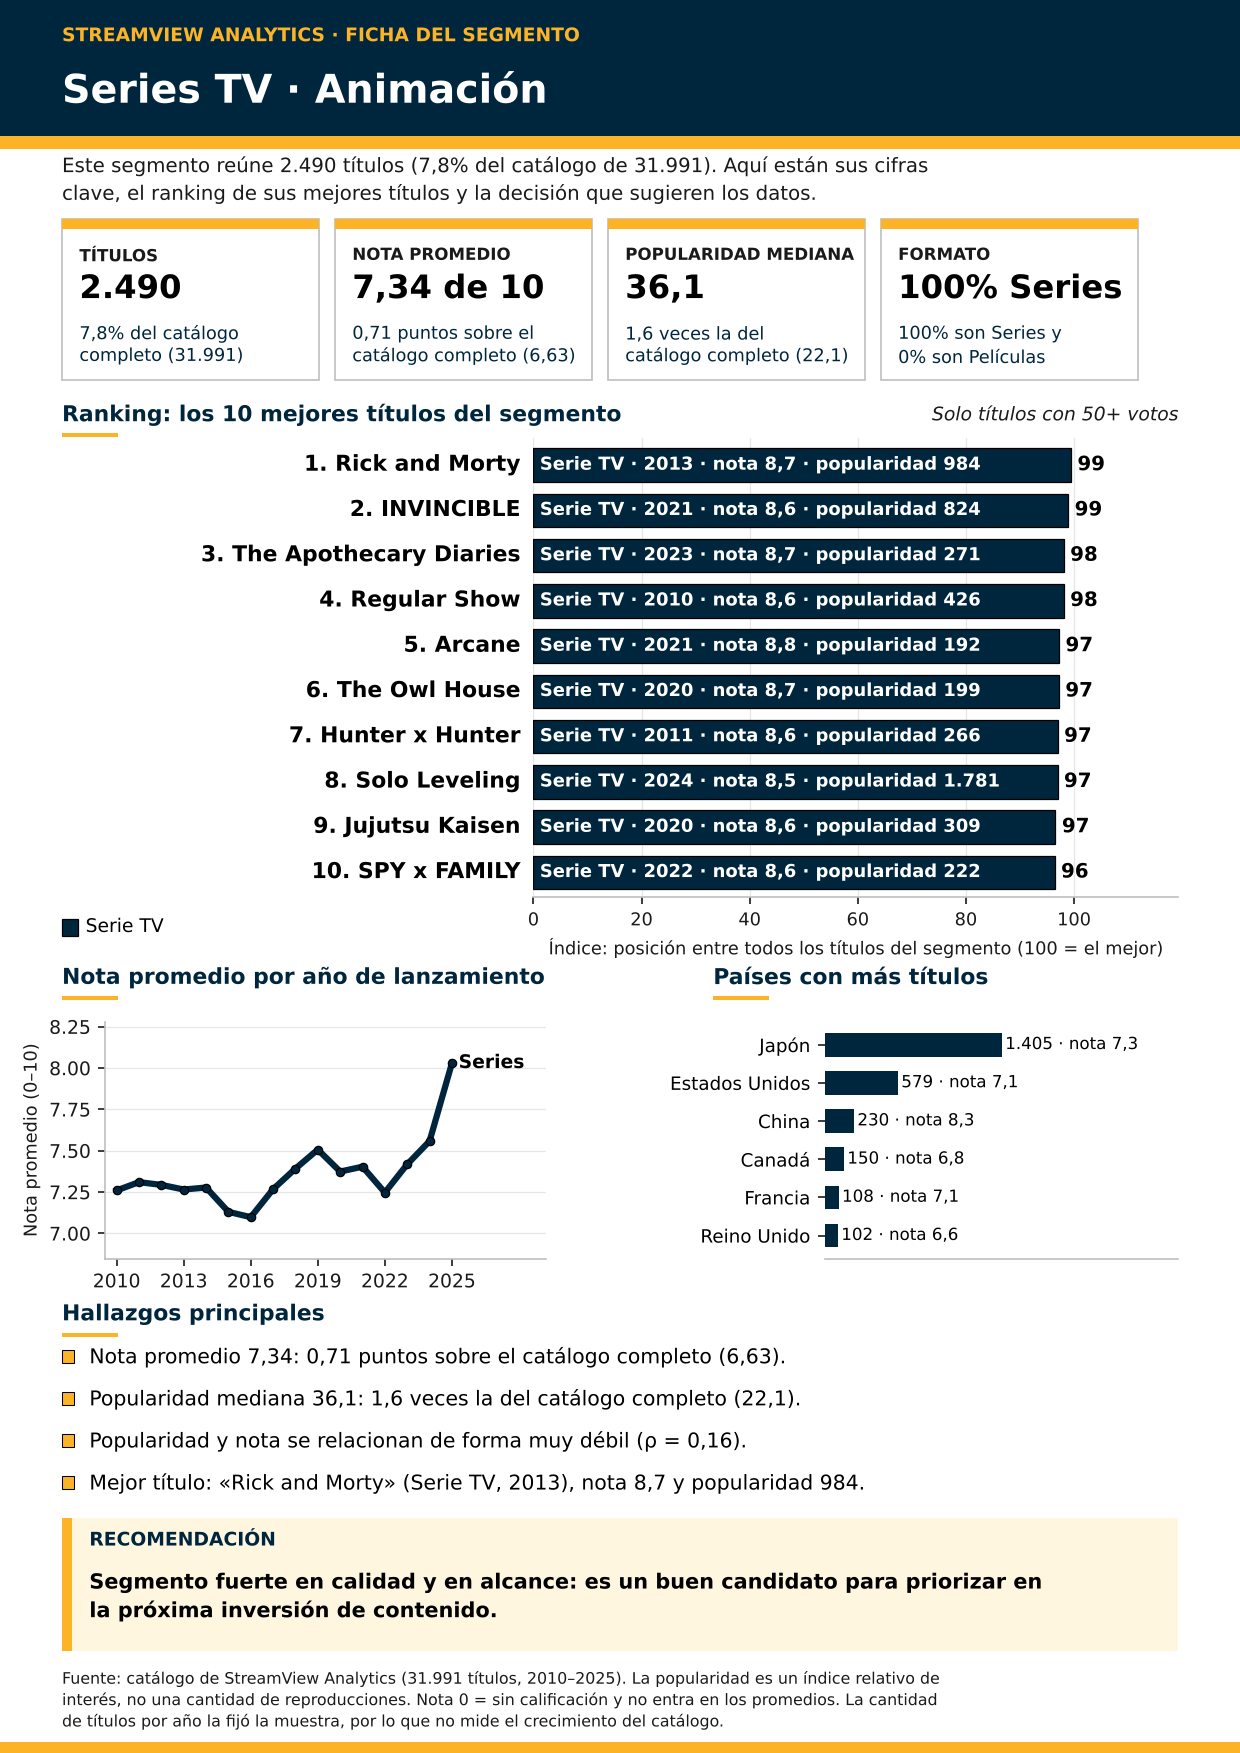

**Cómo se llegó a la recomendación de este ejemplo.** El segmento tiene 2.490 títulos. Su nota promedio está **0,71 puntos sobre** el catálogo y su popularidad mediana es **1,6 veces** la del catálogo. Con los límites de 11.5, el caso es «**calidad y alcance**» y la hoja recomienda: *Segmento fuerte en calidad y en alcance: es un buen candidato para priorizar en la próxima inversión de contenido.*

In [31]:
ej_tipos, ej_gen = ["Serie TV"], ["Animation"]
ej = ud.aplicar_filtros(catalogo, ej_tipos, 2010, 2025, 0, ej_gen)
fig_ej = construir_infografia(ej, catalogo, ej_tipos, 2010, 2025, 0, ej_gen, criterio="indice")
png_ej, _ = exportar(fig_ej)
display(Image(data=png_ej, width=800))

diag_ej = diagnosticar(ej, catalogo)
display(Markdown(f"**Cómo se llegó a la recomendación de este ejemplo.** El segmento tiene {num(len(ej), 0)} títulos. Su nota promedio está **{num(abs(diag_ej['d_nota']))} puntos {'sobre' if diag_ej['d_nota'] > 0 else 'bajo'}** el catálogo "
                 f"y su popularidad mediana es **{num(diag_ej['razon_pop'], 1)} veces** la del catálogo. "
                 f"Con los límites de 11.5, el caso es «**{diag_ej['caso']}**» y la hoja recomienda: *{diag_ej['texto']}*"))

### 11.7 Hazlo tú: elige tus opciones y descarga el PDF
1. Abre la celda siguiente (es un *formulario*: listas y deslizadores en vez de código).
2. Elige formato, años, mínimo de votos, género y criterio de orden (las mismas opciones del panel lateral del dashboard).
3. Ejecútala: verás la **infografía** y el **informe breve**, y se descargará **un solo PDF**. Es el único archivo que genera este notebook.
4. Para otro segmento, cambia las opciones y vuelve a ejecutarla.

Tus opciones: Todo el catálogo · 2015–2025 · 0+ votos · Todos los géneros · orden: Combinado (popularidad + nota)
Títulos que cumplen: 21.991 (con calificación: 18.801)
Fuera de Colab: el PDF quedó guardado como mi_infografia_streamview.pdf


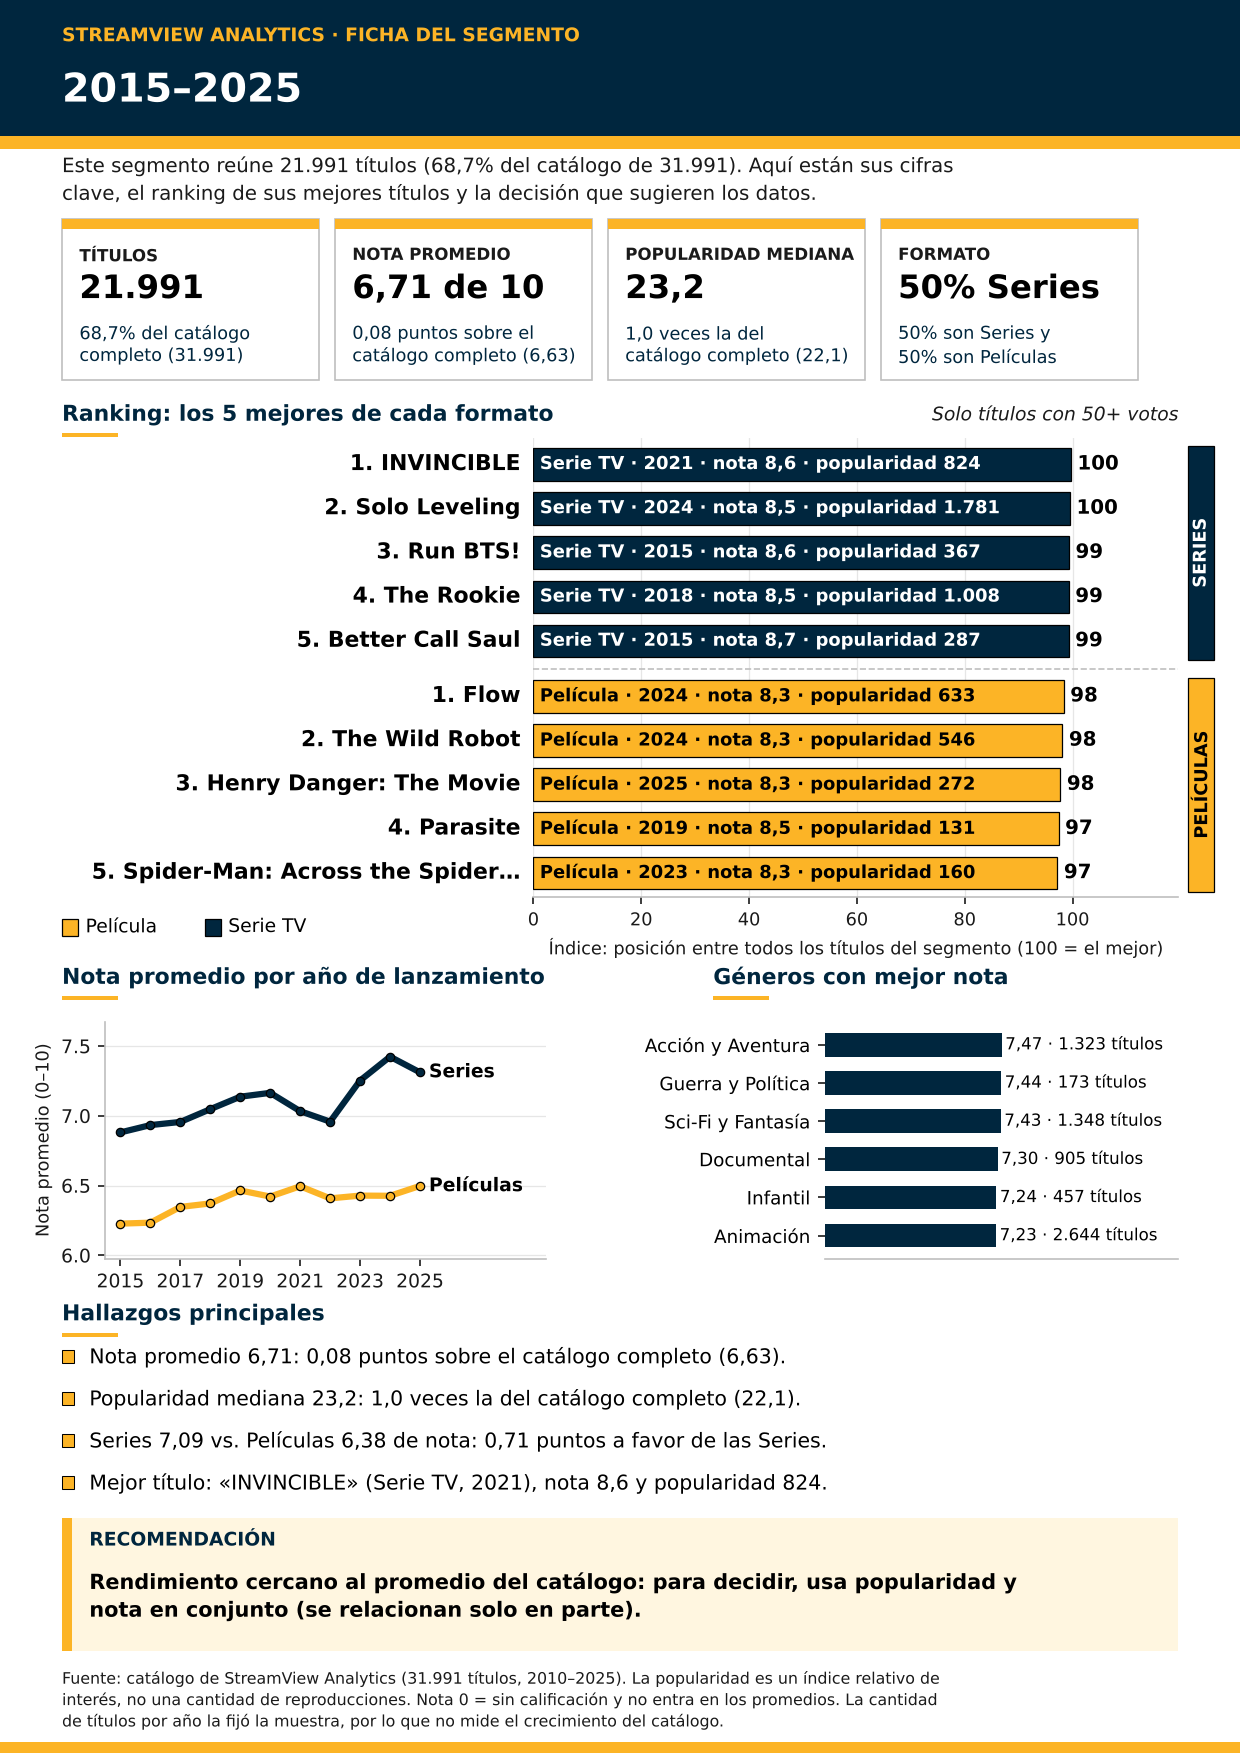

# Informe del segmento: 2015–2025

*StreamView Analytics · generado desde el dashboard con los filtros activos*

> **Resumen.** 21.991 títulos (68,7% del catálogo), nota promedio **6,71** (catálogo 6,63) y popularidad mediana **23,2** (1,0× el catálogo). **Rendimiento cercano al promedio del catálogo: para decidir, usa popularidad y nota en conjunto (se relacionan solo en parte).**

## 1. Segmento analizado

| Parámetro | Valor |
|---|---|
| Formato | Películas, Series TV |
| Años de lanzamiento | 2015–2025 |
| Votos mínimos | 0 |
| Géneros | todos |
| Ranking ordenado por | índice combinado (0–100) |

## 2. Cifras clave

| Indicador | Segmento | Catálogo completo | Diferencia |
|---|---|---|---|
| Títulos | 21.991 | 31.991 | 68,7% del catálogo |
| Con calificación | 85,5% | 85,7% | -0,2 pts |
| Nota promedio (0–10) | 6,71 | 6,63 | +0,08 pts |
| Popularidad mediana | 23,2 | 22,1 | 1,0× |
| Votos por título (mediana) | 40 | 43 | 0,9× |
| Series TV en el segmento | 50% | 50% | — |

## 3. Hallazgos

1. Series 7,09 vs. Películas 6,38 de nota: 0,71 puntos a favor de las Series.
2. Mejor título: «INVINCIBLE» (Serie TV, 2021), nota 8,6 y popularidad 824.
3. Género más frecuente: Drama (10.302 títulos, 47% del segmento).
4. País con más títulos: Estados Unidos (7.499 títulos, 34% del segmento).

## 4. Ranking: los 5 mejores de cada formato (solo con 50+ votos)

Ordenado de mayor a menor por índice combinado (0–100), dentro de cada formato. Para ver solo Películas o solo Series, elige ese formato en el filtro.

| N.º | Título | Formato | Año | Nota | Popularidad | Votos | Índice |
|---|---|---|---|---|---|---|---|
| 1 | INVINCIBLE | Serie TV | 2021 | 8,6 | 824 | 4.660 | 100 |
| 2 | Solo Leveling | Serie TV | 2024 | 8,5 | 1.781 | 797 | 100 |
| 3 | Run BTS! | Serie TV | 2015 | 8,6 | 367 | 362 | 99 |
| 4 | The Rookie | Serie TV | 2018 | 8,5 | 1.008 | 2.289 | 99 |
| 5 | Better Call Saul | Serie TV | 2015 | 8,7 | 287 | 5.475 | 99 |
| 6 | Flow | Película | 2024 | 8,3 | 633 | 1.263 | 98 |
| 7 | The Wild Robot | Película | 2024 | 8,3 | 546 | 4.437 | 98 |
| 8 | Henry Danger: The Movie | Película | 2025 | 8,3 | 272 | 145 | 98 |
| 9 | Parasite | Película | 2019 | 8,5 | 131 | 18.728 | 97 |
| 10 | Spider-Man: Across the Spider-Verse | Película | 2023 | 8,3 | 160 | 7.346 | 97 |

## 5. Recomendación

**Rendimiento cercano al promedio del catálogo: para decidir, usa popularidad y nota en conjunto (se relacionan solo en parte).**

*Por qué:* la nota del segmento está 0,08 puntos sobre el catálogo y su popularidad mediana es 1,0× la del catálogo. Se considera nota alta o baja a partir de ±0,15 puntos y popularidad alta o baja a partir de ×1,15 / ×0,85.

## 6. Cómo leer este informe

- La **popularidad** es un índice relativo de interés, no una cantidad de reproducciones.
- Nota 0 = sin calificación: no entra en los promedios. Una nota con pocos votos es poco confiable, por eso el ranking exige un mínimo de votos.
- El **índice combinado** (0–100) promedia la posición del título en popularidad y en nota.
- La cantidad de títulos por año la fijó la muestra, así que no mide el crecimiento del catálogo.

In [32]:
#@title Elige tus opciones { display-mode: "form" }
formato = "Todo el catálogo"  #@param ["Todo el catálogo", "Solo Películas", "Solo Series TV"]
anio_desde = 2015  #@param {type:"slider", min:2010, max:2025, step:1}
anio_hasta = 2025  #@param {type:"slider", min:2010, max:2025, step:1}
votos_minimos = 0  #@param [0, 10, 50, 100, 200, 500] {type:"raw"}
genero = "Todos los géneros"  #@param ["Todos los géneros", "Acción", "Acción y Aventura", "Animación", "Aventura", "Bélica", "Ciencia ficción", "Comedia", "Crimen", "Documental", "Drama", "Familia", "Fantasía", "Guerra y Política", "Historia", "Infantil", "Misterio", "Música", "Noticias", "Película para TV", "Reality", "Romance", "Sci-Fi y Fantasía", "Suspenso", "Talk show", "Telenovela", "Terror", "Western"]
ordenar_por = "Combinado (popularidad + nota)"  #@param ["Combinado (popularidad + nota)", "Calificación", "Popularidad"]
titulo_infografia = ""  #@param {type:"string"}
descargar_pdf = True  #@param {type:"boolean"}

TIPOS = {"Todo el catálogo": ["Película", "Serie TV"], "Solo Películas": ["Película"], "Solo Series TV": ["Serie TV"]}
EN_INGLES = {ud.es_genero(g): g for g in ud.explode_columna(catalogo, "genres")["genres"].unique()}   # español -> nombre original

tipos_u = TIPOS[formato]
desde, hasta = min(anio_desde, anio_hasta), max(anio_desde, anio_hasta)
generos_u = [] if genero == "Todos los géneros" else [EN_INGLES[genero]]
criterio_u = ud.CRITERIOS_RANKING[ordenar_por]

segmento_u = ud.aplicar_filtros(catalogo, tipos_u, desde, hasta, votos_minimos, generos_u)
print(f"Tus opciones: {formato} · {desde}–{hasta} · {num(votos_minimos, 0)}+ votos · {genero} · orden: {ordenar_por}")
print(f"Títulos que cumplen: {num(len(segmento_u), 0)} (con calificación: {num(len(ud.calificados(segmento_u)), 0)})")
try:
    fig_u = construir_infografia(segmento_u, catalogo, tipos_u, desde, hasta, votos_minimos, generos_u, criterio=criterio_u, titulo=titulo_infografia or None)
    informe_u = construir_informe(segmento_u, catalogo, tipos_u, desde, hasta, votos_minimos, generos_u, criterio=criterio_u, titulo=titulo_infografia or None)
    png_u, pdf_u = exportar(fig_u)
    display(Image(data=png_u, width=900))
    display(Markdown(informe_u))
    ruta_pdf = "mi_infografia_streamview.pdf"
    with open(ruta_pdf, "wb") as f:
        f.write(pdf_u)
    if descargar_pdf:
        try:
            from google.colab import files
            files.download(ruta_pdf)                      # única descarga del notebook
        except ImportError:
            print(f"Fuera de Colab: el PDF quedó guardado como {ruta_pdf}")
    else:
        print("Descarga desactivada: marca «descargar_pdf» si quieres el PDF.")
except ValueError as e:                                   # menos de 5 títulos calificados
    print("No se generó la infografía:", e)

## 12. Verificaciones y conclusión (IE22)
Pruebas automáticas: si alguna falla, el notebook se detiene con un aviso. Así cada cifra citada arriba queda respaldada.

In [33]:
def verificar(nombre, condicion):
    assert bool(condicion), f"FALLÓ: {nombre}"
    print("✔", nombre)

verificar("El catálogo no tiene títulos repetidos (id_unico único)", catalogo["id_unico"].is_unique)
verificar("El catálogo = películas + series limpias", len(catalogo) == len(peliculas) + len(series))
verificar("Ninguna nota 0 entra en los promedios", (cal["vote_average"] > 0).all())
verificar("Las Series superan a las Películas en nota promedio", brecha_nota > 0)
verificar("La ventaja de Series existe incluso SIN mínimo de votos", t_b.loc[0, "Ventaja de Series"] > 0)
verificar("Las Series ganan en todos los años", anios_ganan == len(t2))
verificar("Las Series ganan en todos los géneros comparables", generos_ganan == len(t3))
verificar("La correlación sube al exigir 50+ votos en Series", t_c.loc["50+ votos", "Series TV"] > t_c.loc["0+ votos", "Series TV"])
verificar("Solo 8 géneros comparables", len(t3) == 8)
verificar("El ROI usa solo películas con dinero informado", (fin["budget"] >= 100_000).all() and (fin["revenue"] >= 100_000).all())
verificar("El índice combinado del notebook coincide con el del dashboard", list(top10_ind["title"]) == list(ud.indice_compuesto(catalogo, 50, 10)["title"]))
print("\nTodas las verificaciones pasaron.")

✔ El catálogo no tiene títulos repetidos (id_unico único)
✔ El catálogo = películas + series limpias
✔ Ninguna nota 0 entra en los promedios
✔ Las Series superan a las Películas en nota promedio
✔ La ventaja de Series existe incluso SIN mínimo de votos
✔ Las Series ganan en todos los años
✔ Las Series ganan en todos los géneros comparables
✔ La correlación sube al exigir 50+ votos en Series
✔ Solo 8 géneros comparables
✔ El ROI usa solo películas con dinero informado
✔ El índice combinado del notebook coincide con el del dashboard

Todas las verificaciones pasaron.


### Preguntas que pueden hacerte y dónde está la respuesta
| Pregunta | Respuesta corta | Evidencia |
|---|---|---|
| ¿Por qué recomiendan Series? | Tienen mejor nota en promedio, en todos los años y en todos los géneros comparables | 4.1, 4.2, 4.3 |
| ¿Y si las notas altas vienen de pocos votos? | La ventaja existe también sin mínimo de votos | Sección 7, prueba 1 |
| ¿Por qué usan la mediana en popularidad? | El promedio lo inflan pocos títulos enormes | 3.4 |
| ¿Por qué escala logarítmica? | En escala lineal los títulos gigantes aplastan al resto | 3.4 |
| ¿Qué significa ρ (rho)? | Cuánto se parecen las posiciones de dos variables: 0 = nada, 1 = idénticas | 3.5 y 4.4 |
| ¿Lo popular es lo mejor evaluado? | Solo en parte: dentro de cada formato la relación es débil | 4.4 |
| ¿Por qué solo 8 géneros? | Son los únicos con el mismo nombre en Películas y Series | 4.3 |
| ¿Por qué necesitan un mínimo de votos? | Para rankings, países y correlación; no para la decisión principal | Sección 7 |
| ¿Por qué el ROI no es el criterio principal? | Solo una parte de las películas informa dinero y ninguna serie | 4.6 |
| ¿Qué limitaciones tiene el análisis? | Ver «Conclusión» (abajo) | Sección 12 |

### Conclusión
1. **Las Series TV están mejor evaluadas que las Películas**, de forma constante (todos los años y todos los géneros) y sin depender de un mínimo de votos.
2. **La popularidad no basta** para elegir contenido: se relaciona poco con la nota dentro de cada formato. Para comparar títulos usamos un índice combinado.
3. **El mínimo de votos es una regla de confiabilidad**: necesaria en rankings, correlaciones y comparación de países; no necesaria para la decisión principal.
4. **Limitaciones:** la nota es la del público (no ventas ni horas vistas); el dinero solo existe para una parte de las películas; el catálogo es una muestra por año, por lo que la cantidad de títulos por año no mide el crecimiento real.

*Este notebook se complementa con el dashboard (exploración), el informe PDF y el README (estructura del proyecto y orden de carpetas).*

## 13. Referencias
### 13.1 Librerías utilizadas
La celda siguiente muestra las **versiones realmente instaladas** en el entorno donde se ejecuta el notebook.

In [ ]:
import sys
from importlib.metadata import version, PackageNotFoundError

usos = [
    ("pandas", "Carga, limpieza, unión y resumen de los datos; tablas del análisis"),
    ("numpy", "Cálculos numéricos, histogramas y muestreo"),
    ("matplotlib", "Gráficos estáticos (secciones 3 y 4) y diseño de la infografía en A4"),
    ("plotly", "Gráficos interactivos (sección 6): tooltips, zoom, leyenda y botones"),
    ("ipython", "Presentación de tablas, texto con formato e imágenes dentro del notebook"),
]
filas = []
for nombre, uso in usos:
    try:
        v = version(nombre)
    except PackageNotFoundError:
        v = "no instalada"
    filas.append({"Librería": nombre, "Versión instalada": v, "Uso en este notebook": uso})
filas.insert(0, {"Librería": "Python", "Versión instalada": sys.version.split()[0], "Uso en este notebook": "Lenguaje de programación"})
display(pd.DataFrame(filas).set_index("Librería"))
print("Biblioteca estándar de Python: os, io, textwrap, types, warnings.")
print("Entorno de ejecución: Google Colab.")

> El dashboard (Streamlit) que complementa este notebook usa además *Streamlit* y *Plotly Express*; sus dependencias se documentan en el `README` y en el archivo `requirements.txt` del proyecto, no aquí.

### 13.2 Referencias bibliográficas
- Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
- Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90–95. https://doi.org/10.1109/MCSE.2007.55
- McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 56–61.
- Pérez, F., & Granger, B. E. (2007). IPython: A system for interactive scientific computing. *Computing in Science & Engineering, 9*(3), 21–29.
- Pinto, G. (2026). *Caso semestral StreamView Analytics* [Material docente]. ADY1104 Visualización de Datos, Duoc UC.
- Pinto, G. (2026). *Netflix Movies Detailed up to 2025* [Conjunto de datos, archivo CSV]. ADY1104 Visualización de Datos, Duoc UC.
- Pinto, G. (2026). *Netflix TV Shows Detailed up to 2025* [Conjunto de datos, archivo CSV]. ADY1104 Visualización de Datos, Duoc UC.
- Plotly Technologies Inc. (2015). *Collaborative data science*. Plotly. https://plot.ly
- Python Software Foundation. (s. f.). *Python language reference*. https://www.python.org
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.